# 01_data_audit

# GFZ Data Audit

First cell: set up the imports and point to the raw GFZ Kp file.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

RAW = Path("../data/raw")
GFZ_FILE = RAW / "kp" / "gfz_Kp_ap_Ap_SN_F107_since_1932.txt"

print("exists:", GFZ_FILE.exists())
print("size (MB):", round(GFZ_FILE.stat().st_size / 1e6, 2))

exists: True
size (MB): 5.51


Open the raw GFZ file and look at its header and the first and last data lines.

In [2]:
with open(GFZ_FILE) as f:
    lines = f.readlines()

header = [l for l in lines if l.startswith("#")]
data_lines = [l for l in lines if not l.startswith("#")]

print("total lines     :", len(lines))
print("header lines    :", len(header))
print("data lines      :", len(data_lines))
print()
print("--- column names line ---")
print(header[-1])
print("--- D flag explanation ---")
for l in header:
    if "D indicates" in l:
        print(l)
print("--- first data line ---")
print(data_lines[0])
print("--- last data line ---")
print(data_lines[-1])

total lines     : 34666
header lines    : 40
data lines      : 34626

--- column names line ---
#YYY MM DD  days  days_m  Bsr dB    Kp1    Kp2    Kp3    Kp4    Kp5    Kp6    Kp7    Kp8  ap1  ap2  ap3  ap4  ap5  ap6  ap7  ap8    Ap  SN F10.7obs F10.7adj D

--- D flag explanation ---
# D indicates if the Kp and SN values are definitive or preliminary. D=0: Kp and SN preliminary; D=1: Kp definitive, SN preliminary; D=2 Kp and SN definitive

--- first data line ---
1932 01 01     0     0.5 1352 10  3.333  2.667  2.333  2.667  3.333  2.667  3.333  3.333   18   12    9   12   18   12   18   18    15  22     -1.0     -1.0 2

--- last data line ---
2026 10 19 34625 34625.5 2634 21  0.000  0.000  0.000  0.333  0.333  0.333  0.333  0.333    0    0    0    2    2    2    2    2     1  66    121.4    120.5 0



Read the file into a table with proper column names.

In [3]:
cols = (
    ["year", "month", "day", "days", "days_m", "bsr", "db"]
    + [f"Kp{i}" for i in range(1, 9)]
    + [f"ap{i}" for i in range(1, 9)]
    + ["Ap", "SN", "F107obs", "F107adj", "D"]
)

gfz_raw = pd.read_csv(GFZ_FILE, sep=r"\s+", comment="#", header=None, names=cols)

gfz_raw["date"] = pd.to_datetime(gfz_raw[["year", "month", "day"]])

print("shape:", gfz_raw.shape)
print()
print(gfz_raw.dtypes)
print()
print(gfz_raw.head(3))
print()
print(gfz_raw.tail(3))

shape: (34626, 29)

year                int64
month               int64
day                 int64
days                int64
days_m            float64
bsr                 int64
db                  int64
Kp1               float64
Kp2               float64
Kp3               float64
Kp4               float64
Kp5               float64
Kp6               float64
Kp7               float64
Kp8               float64
ap1                 int64
ap2                 int64
ap3                 int64
ap4                 int64
ap5                 int64
ap6                 int64
ap7                 int64
ap8                 int64
Ap                  int64
SN                  int64
F107obs           float64
F107adj           float64
D                   int64
date       datetime64[us]
dtype: object

   year  month  day  days  days_m   bsr  db    Kp1    Kp2    Kp3    Kp4    Kp5    Kp6    Kp7    Kp8  ap1  ap2  ap3  ap4  ap5  ap6  ap7  ap8  Ap  SN  F107obs  F107adj  D       date
0  1932      1    1     0     0

Check that the dates are continuous, with no gaps or duplicates.

In [4]:
d = gfz_raw["date"]

print("first date :", d.min().date())
print("last date  :", d.max().date())
print("rows       :", len(d))
print("duplicates :", d.duplicated().sum())
print("sorted     :", d.is_monotonic_increasing)

expected = pd.date_range(d.min(), d.max(), freq="D")
missing_days = expected.difference(d)
print("expected days:", len(expected))
print("missing days :", len(missing_days))
print(missing_days[:10])

# the file's own 'days' counter should equal days since 1932-01-01
check = (d - pd.Timestamp("1932-01-01")).dt.days
print("'days' column consistent with date:", (check == gfz_raw["days"]).all())

first date : 1932-01-01
last date  : 2026-10-19
rows       : 34626
duplicates : 0
sorted     : True
expected days: 34626
missing days : 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')
'days' column consistent with date: True


Count the missing values (coded as -1), over all years and inside my project window.

In [5]:
kp_cols = [f"Kp{i}" for i in range(1, 9)]
ap_cols = [f"ap{i}" for i in range(1, 9)]
check_cols = kp_cols + ap_cols + ["Ap", "SN", "F107obs", "F107adj"]

# project window: DSCOVR operational from 2016-07-26 onwards
win = gfz_raw[gfz_raw["date"] >= "2016-07-26"]

summary = pd.DataFrame({
    "missing_all_years": (gfz_raw[check_cols] == -1).sum(),
    "missing_in_window": (win[check_cols] == -1).sum(),
})
print("rows in window:", len(win))
print(summary)

print()
print("F10.7obs: first valid date  :", gfz_raw.loc[gfz_raw["F107obs"] != -1, "date"].min().date())
print("F10.7obs: last missing date :", gfz_raw.loc[gfz_raw["F107obs"] == -1, "date"].max().date())

print()
print("any other negative values (not -1)?")
print((gfz_raw[check_cols] < 0).sum().loc[lambda s: s > 0].to_dict())

rows in window: 3738
         missing_all_years  missing_in_window
Kp1                      0                  0
Kp2                      0                  0
Kp3                      0                  0
Kp4                      0                  0
Kp5                      0                  0
Kp6                      0                  0
Kp7                      0                  0
Kp8                      0                  0
ap1                      0                  0
ap2                      0                  0
ap3                      0                  0
ap4                      0                  0
ap5                      0                  0
ap6                      0                  0
ap7                      0                  0
ap8                      0                  0
Ap                       0                  0
SN                       0                  0
F107obs               6178                  9
F107adj               6178                  9

F10.7obs: fi

List the few days in the window where F10.7 is missing, and see which Kp quality flag (D) applies to which part of the window.

In [6]:
print("F10.7 missing days inside the window:")
print(win.loc[win["F107obs"] == -1, ["date", "F107obs", "F107adj", "D"]].to_string(index=False))

print()
print("D flag counts in window (0 = Kp, SN preliminary; 1 = Kp definitive; 2 = both definitive):")
print(win["D"].value_counts().sort_index())

print()
print("date range per D value in window:")
print(win.groupby("D")["date"].agg(["min", "max", "count"]))

F10.7 missing days inside the window:
      date  F107obs  F107adj  D
2020-10-23     -1.0     -1.0  2
2020-12-17     -1.0     -1.0  2
2020-12-18     -1.0     -1.0  2
2021-05-09     -1.0     -1.0  2
2021-06-16     -1.0     -1.0  2
2024-08-26     -1.0     -1.0  2
2025-02-12     -1.0     -1.0  2
2025-02-17     -1.0     -1.0  2
2026-05-09     -1.0     -1.0  1

D flag counts in window (0 = Kp, SN preliminary; 1 = Kp definitive; 2 = both definitive):
D
0      19
1     183
2    3536
Name: count, dtype: int64

date range per D value in window:
         min        max  count
D                             
0 2026-10-01 2026-10-19     19
1 2026-04-01 2026-09-30    183
2 2016-07-26 2026-03-31   3536


Check the Kp values make sense, count storm days by NOAA level, and look at May 2024.

In [7]:
kp = win[kp_cols]

print("Kp min:", kp.min().min(), "| Kp max:", kp.max().max())
print("values outside 0-9:", ((kp < 0) | (kp > 9)).sum().sum())

# Kp is reported on a 1/3 grid: 0, 0.333, 0.667, 1.0 ...
on_grid = (kp * 3 - (kp * 3).round()).abs() < 0.01
print("values off the 1/3 grid:", (~on_grid).sum().sum())

# daily max Kp and storm-level day counts
kp_daily_max = kp.max(axis=1)
print()
print("daily max Kp, summary:")
print(kp_daily_max.describe().round(2))

print()
print("days reaching NOAA storm levels (daily max Kp):")
for lvl, name in [(5, "G1 (Kp>=5)"), (6, "G2 (Kp>=6)"), (7, "G3 (Kp>=7)"), (8, "G4 (Kp>=8)"), (9, "G5 (Kp=9)")]:
    print(f"  {name:12s}: {(kp_daily_max >= lvl - 0.01).sum()}")

print()
print("2024-05-10 to 2024-05-12, daily max Kp:")
m = win["date"].between("2024-05-10", "2024-05-12")
print(pd.Series(kp_daily_max[m].values, index=win.loc[m, "date"].dt.date))

Kp min: 0.0 | Kp max: 9.0
values outside 0-9: 0
values off the 1/3 grid: 0

daily max Kp, summary:
count    3738.00
mean        2.91
std         1.36
min         0.00
25%         2.00
50%         2.67
75%         3.67
max         9.00
dtype: float64

days reaching NOAA storm levels (daily max Kp):
  G1 (Kp>=5)  : 318
  G2 (Kp>=6)  : 97
  G3 (Kp>=7)  : 39
  G4 (Kp>=8)  : 13
  G5 (Kp=9)   : 1

2024-05-10 to 2024-05-12, daily max Kp:
date
2024-05-10    8.667
2024-05-11    9.000
2024-05-12    7.000
dtype: float64


Plot the daily maximum Kp over the whole window, and the 3-hourly Kp during the May 2024 storm.

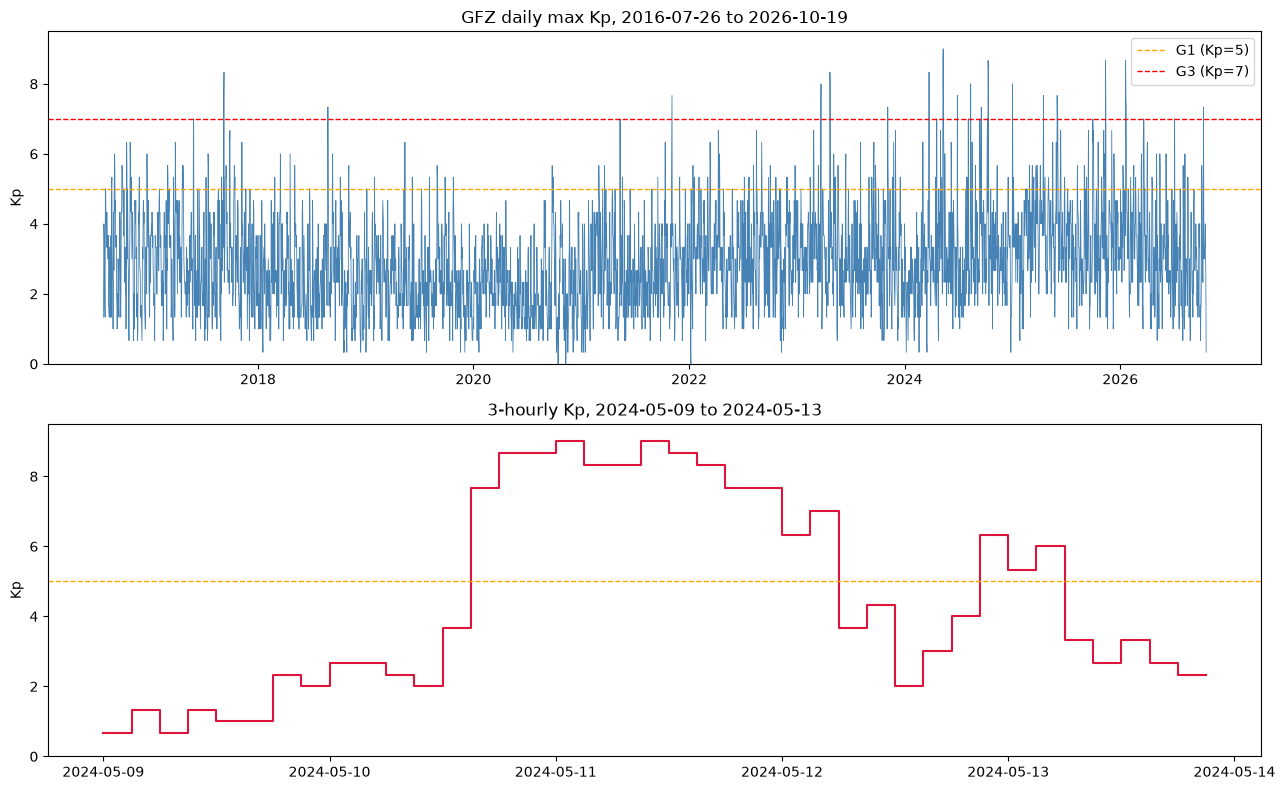

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Panel 1: daily max Kp over the project window
axes[0].plot(win["date"], kp_daily_max.values, lw=0.6, color="steelblue")
axes[0].axhline(5, color="orange", ls="--", lw=1, label="G1 (Kp=5)")
axes[0].axhline(7, color="red", ls="--", lw=1, label="G3 (Kp=7)")
axes[0].set_title("GFZ daily max Kp, 2016-07-26 to 2026-10-19")
axes[0].set_ylabel("Kp")
axes[0].set_ylim(0, 9.5)
axes[0].legend(loc="upper right")

# Panel 2: 3-hourly Kp across the May 2024 storm
may = win[win["date"].between("2024-05-09", "2024-05-13")]
kp3h = may[kp_cols].to_numpy().ravel()
t3h = pd.to_datetime(np.repeat(may["date"].to_numpy(), 8)) + pd.to_timedelta(np.tile(np.arange(8) * 3, len(may)), unit="h")
axes[1].step(t3h, kp3h, where="post", color="crimson")
axes[1].axhline(5, color="orange", ls="--", lw=1)
axes[1].set_title("3-hourly Kp, 2024-05-09 to 2024-05-13")
axes[1].set_ylabel("Kp")
axes[1].set_ylim(0, 9.5)

plt.tight_layout()
plt.show()

### GFZ audit findings

- Source: GFZ Potsdam, `Kp_ap_Ap_SN_F107_since_1932.txt`, downloaded 2026-10-20.
- 34,626 daily rows, 1932-01-01 to 2026-10-19. No duplicate or missing dates. 3-hourly Kp (8 per day).
- Missing values are coded as -1, not blank. Must be converted to NaN before analysis.
- Kp, ap, Ap, SN: no missing values in any year. F10.7: 6,178 missing, mostly pre-1947 (series starts 1947-02-14).
- Project window (2016-07-26 onward, 3,738 days): 9 isolated F10.7 gap days (longest run: 2 days), fillable by interpolation.
- Kp quality flag (D): definitive through 2026-09-30; preliminary only for 2026-10-01 to 2026-10-19 (19 days). May 2024 is definitive.
- Kp values valid: range 0–9, all on the 1/3 grid.
- Storm days are rare: 318 of 3,738 days (8.5%) reach G1+, 1 reaches G5 (2024-05-11).
- Activity follows the solar cycle (minimum ~2019–2020, high 2023–2026).
- Decision: use Kp as-is for the project window; convert -1 to NaN for F10.7 only; note preliminary status of the last 19 days.

# CelesTrak Data Audit

Load the CelesTrak file and look at its shape, its columns and the May 2024 rows.

In [9]:
CT_FILE = RAW / "f107" / "celestrak_SW-All.csv"

ct_raw = pd.read_csv(CT_FILE, parse_dates=["DATE"])

print("shape:", ct_raw.shape)
print("first / last date:", ct_raw["DATE"].min().date(), "/", ct_raw["DATE"].max().date())
print()
print(ct_raw.dtypes)
print()
print("F10.7_DATA_TYPE counts:")
print(ct_raw["F10.7_DATA_TYPE"].value_counts())
print()
print(ct_raw.loc[ct_raw["DATE"].between("2024-05-10", "2024-05-12"),
                 ["DATE", "KP1", "KP2", "KP3", "KP4", "KP5", "KP6", "KP7", "KP8", "F10.7_OBS", "F10.7_DATA_TYPE"]])

shape: (25444, 31)
first / last date: 1957-10-01 / 2041-10-01

DATE                  datetime64[us]
BSRN                           int64
ND                             int64
KP1                          float64
KP2                          float64
KP3                          float64
KP4                          float64
KP5                          float64
KP6                          float64
KP7                          float64
KP8                          float64
KP_SUM                       float64
AP1                          float64
AP2                          float64
AP3                          float64
AP4                          float64
AP5                          float64
AP6                          float64
AP7                          float64
AP8                          float64
AP_AVG                       float64
CP                           float64
C9                           float64
ISN                            int64
F10.7_OBS                    float64
F10.7_ADJ   

Check CelesTrak's dates and find where the observed data ends and the predictions begin.

In [10]:
d = ct_raw["DATE"]
print("duplicates:", d.duplicated().sum(), "| sorted:", d.is_monotonic_increasing)

expected = pd.date_range(d.min(), d.max(), freq="D")
print("expected days:", len(expected), "| rows:", len(d), "| missing days:", len(expected.difference(d)))

print()
print("date range per F10.7_DATA_TYPE:")
print(ct_raw.groupby("F10.7_DATA_TYPE")["DATE"].agg(["min", "max", "count"]))

print()
print("rows with Kp present (KP1 not null) per type:")
print(ct_raw.groupby("F10.7_DATA_TYPE")["KP1"].apply(lambda s: s.notna().sum()))

last_obs = ct_raw.loc[ct_raw["F10.7_DATA_TYPE"] == "OBS", "DATE"].max()
print()
print("last OBS date:", last_obs.date())
print("Kp present after last OBS date:")
after = ct_raw[(ct_raw["DATE"] > last_obs) & ct_raw["KP1"].notna()]
print(after[["DATE", "KP1", "KP8", "F10.7_DATA_TYPE"]].to_string(index=False))

duplicates: 0 | sorted: True
expected days: 30682 | rows: 25444 | missing days: 5238

date range per F10.7_DATA_TYPE:
                       min        max  count
F10.7_DATA_TYPE                             
INT             1957-12-25 2026-05-09     60
OBS             1957-10-01 2026-10-19  25161
PRD             2026-10-20 2026-12-03     45
PRM             2027-01-01 2041-10-01    178

rows with Kp present (KP1 not null) per type:
F10.7_DATA_TYPE
INT       60
OBS    25161
PRD       45
PRM        0
Name: KP1, dtype: int64

last OBS date: 2026-10-19
Kp present after last OBS date:
      DATE  KP1  KP8 F10.7_DATA_TYPE
2026-10-20 10.0 37.0             PRD
2026-10-21 30.0 30.0             PRD
2026-10-22 24.0 24.0             PRD
2026-10-23 13.0 13.0             PRD
2026-10-24 30.0 30.0             PRD
2026-10-25 22.0 22.0             PRD
2026-10-26 13.0 13.0             PRD
2026-10-27 13.0 13.0             PRD
2026-10-28 13.0 13.0             PRD
2026-10-29 13.0 13.0             PRD
2026-10

Compare CelesTrak's Kp, Ap and F10.7 with the GFZ values.

In [11]:
# observed CelesTrak rows only, project window, Kp scaled back to Kp units
ct = ct_raw[(ct_raw["F10.7_DATA_TYPE"].isin(["OBS", "INT"])) & (ct_raw["DATE"] >= "2016-07-26")].copy()
ct_kp = ct[["DATE"] + [f"KP{i}" for i in range(1, 9)]].set_index("DATE") / 10
ct_kp.columns = kp_cols

gz_kp = win.set_index("date")[kp_cols]

both = ct_kp.index.intersection(gz_kp.index)
diff = (ct_kp.loc[both] - gz_kp.loc[both]).abs()
print("days compared:", len(both))
print("Kp max abs difference   :", round(diff.max().max(), 3))
print("Kp slots differing > 0.05:", (diff > 0.05).sum().sum(), "of", diff.size)

# F10.7 and daily Ap
ct_i = ct.set_index("DATE")
f_ct = ct_i.loc[both, "F10.7_OBS"]
f_gz = win.set_index("date").loc[both, "F107obs"].replace(-1, np.nan)
fd = (f_ct - f_gz).abs()
print()
print("F10.7: days where both present :", fd.notna().sum())
print("F10.7: max abs difference     :", round(fd.max(), 2))
print("F10.7: days differing > 0.1   :", (fd > 0.1).sum())
print("F10.7: GFZ missing but CelesTrak has a value:", (f_gz.isna() & f_ct.notna()).sum())
print(ct_i.loc[both][f_gz.isna()][["F10.7_OBS", "F10.7_DATA_TYPE"]])

ap_d = (ct_i.loc[both, "AP_AVG"] - win.set_index("date").loc[both, "Ap"]).abs()
print()
print("Ap daily: max abs diff", ap_d.max(), "| days differing:", (ap_d > 0).sum())

days compared: 3738
Kp max abs difference   : 0.033
Kp slots differing > 0.05: 0 of 29904

F10.7: days where both present : 3729
F10.7: max abs difference     : 2.9
F10.7: days differing > 0.1   : 15
F10.7: GFZ missing but CelesTrak has a value: 9
            F10.7_OBS F10.7_DATA_TYPE
2020-10-23       73.5             INT
2020-12-17       81.8             INT
2020-12-18       81.8             INT
2021-05-09       76.2             INT
2021-06-16       80.3             INT
2024-08-26      227.0             INT
2025-02-12      163.4             INT
2025-02-17      181.8             INT
2026-05-09      122.6             INT

Ap daily: max abs diff 0.0 | days differing: 0


Look at the 15 days where CelesTrak and GFZ disagree on F10.7.

In [12]:
bad = fd[fd > 0.1].index

out = pd.DataFrame({
    "celestrak": f_ct.loc[bad],
    "gfz": f_gz.loc[bad],
    "abs_diff": fd.loc[bad].round(2),
    "ct_type": ct_i.loc[bad, "F10.7_DATA_TYPE"],
    "gfz_D": win.set_index("date").loc[bad, "D"],
})
print(out.to_string())

print()
print("diff summary (all 15):")
print(out["abs_diff"].describe().round(2))
print()
print("CelesTrak F10.7_ADJ vs GFZ F107adj on the same days:")
adj = pd.DataFrame({
    "ct_adj": ct_i.loc[bad, "F10.7_ADJ"],
    "gfz_adj": win.set_index("date").loc[bad, "F107adj"],
})
print(adj.to_string())

            celestrak    gfz  abs_diff ct_type  gfz_D
2018-02-20       70.5   67.8       2.7     OBS      2
2018-02-22       69.7   68.4       1.3     OBS      2
2018-02-23       70.0   67.6       2.4     OBS      2
2018-02-24       70.0   68.2       1.8     OBS      2
2018-02-25       69.2   67.2       2.0     OBS      2
2018-02-26       72.0   69.8       2.2     OBS      2
2018-02-27       70.0   67.9       2.1     OBS      2
2018-02-28       69.9   68.8       1.1     OBS      2
2019-02-06       71.3   69.8       1.5     OBS      2
2019-02-08       71.8   70.0       1.8     OBS      2
2020-05-14       67.2   67.6       0.4     OBS      2
2021-03-02       75.6   74.7       0.9     OBS      2
2022-10-23      105.5  108.4       2.9     OBS      2
2023-01-08      182.5  183.8       1.3     OBS      2
2023-02-18      167.2  167.4       0.2     OBS      2

diff summary (all 15):
count    15.00
mean      1.64
std       0.79
min       0.20
25%       1.20
50%       1.80
75%       2.15
max    

### CelesTrak audit findings

- Source: CelesTrak `SW-All.csv`, downloaded 2026-10-20. 25,444 rows, 1957-10-01 to 2041-10-01. Identical copy stored in `raw/kp/` and `raw/f107/`.
- Kp is stored as Kp x 10, rounded (87 = 8.667). Divide by 10 before use.
- Observed record (`OBS` + `INT`) ends 2026-10-19. `PRD` (45 daily forecast rows, with Kp) and `PRM` (178 monthly rows, no Kp) are predictions and must be dropped. PRD Kp values repeat in a persistence-like pattern and carry no information.
- The 5,238 "missing days" are all in the monthly prediction tail; the observed record is continuous.
- Kp: matches GFZ in all 29,904 slots of the project window (max diff 0.033 = rounding). Ap: identical.
- F10.7: matches GFZ on 3,714 of 3,729 shared days. 15 days differ by 0.2-2.9 sfu (mean 1.6), both sources flagging them as final/observed. 8 are in 2018-02-20 to 2018-02-28. Cause not identified. Impact negligible (0.4% of days, under 3 sfu).
- CelesTrak fills the 9 GFZ F10.7 gap days with interpolated values (`INT`).
- Decision: F10.7 from CelesTrak (observed rows only, plus INT days flagged as interpolated); Kp from GFZ; GFZ F10.7 kept as cross-check.

# Kyoto Dst Data Audit

Load all the yearly Kyoto Dst files into one table.

In [13]:
dst_files = sorted((RAW / "dst").glob("kyoto_hour_dst_20*.csv"))
print("files:", [f.name for f in dst_files])

dst_raw = pd.concat(
    [pd.read_csv(f, header=None, names=["time", "dst", "version"], parse_dates=["time"]) for f in dst_files],
    ignore_index=True,
)

print()
print("shape:", dst_raw.shape)
print("first / last timestamp:", dst_raw["time"].min(), "/", dst_raw["time"].max())
print()
print(dst_raw.dtypes)
print()
print(dst_raw.head(3))
print()
print(dst_raw.tail(3))
print()
print("version code counts:")
print(dst_raw["version"].value_counts().sort_index())

files: ['kyoto_hour_dst_2016.csv', 'kyoto_hour_dst_2017.csv', 'kyoto_hour_dst_2018.csv', 'kyoto_hour_dst_2019.csv', 'kyoto_hour_dst_2020.csv', 'kyoto_hour_dst_2021.csv', 'kyoto_hour_dst_2022.csv', 'kyoto_hour_dst_2023.csv', 'kyoto_hour_dst_2024.csv', 'kyoto_hour_dst_2025.csv', 'kyoto_hour_dst_2026.csv']

shape: (90327, 3)
first / last timestamp: 2016-07-01 00:29:30+00:00 / 2026-10-20 14:29:30+00:00

time       datetime64[us, UTC]
dst                      int64
version                  int64
dtype: object

                       time  dst  version
0 2016-07-01 00:29:30+00:00   -1       20
1 2016-07-01 01:29:30+00:00   -3       20
2 2016-07-01 02:29:30+00:00   -4       20

                           time  dst  version
90324 2026-10-20 12:29:30+00:00   20        0
90325 2026-10-20 13:29:30+00:00   12        0
90326 2026-10-20 14:29:30+00:00    0        0

version code counts:
version
0       471
10    50376
20    39480
Name: count, dtype: int64


Check Dst for gaps and fill values, and find where the final, provisional and real-time data start and end.

In [14]:
t = dst_raw["time"]
print("duplicates:", t.duplicated().sum(), "| sorted:", t.is_monotonic_increasing)

expected = pd.date_range(t.min(), t.max(), freq="h")
print("expected hours:", len(expected), "| rows:", len(t), "| missing hours:", len(expected.difference(t)))
print("missing sample:", list(expected.difference(t)[:5]))

print()
print("fill value 99999 present:", (dst_raw["dst"] == 99999).sum())
print("Dst min / max:", dst_raw["dst"].min(), "/", dst_raw["dst"].max())

print()
print("date range per version code:")
print(dst_raw.groupby("version")["time"].agg(["min", "max", "count"]))

print()
print("version code during May 2024 storm:")
m = dst_raw[dst_raw["time"].between("2024-05-10", "2024-05-13")]
print(m["version"].value_counts())

duplicates: 0 | sorted: True
expected hours: 90327 | rows: 90327 | missing hours: 0
missing sample: []

fill value 99999 present: 0
Dst min / max: -406 / 71

date range per version code:
                              min                       max  count
version                                                           
0       2026-10-01 00:29:30+00:00 2026-10-20 14:29:30+00:00    471
10      2021-01-01 00:29:30+00:00 2026-09-30 23:29:30+00:00  50376
20      2016-07-01 00:29:30+00:00 2020-12-31 23:29:30+00:00  39480

version code during May 2024 storm:
version
10    72
Name: count, dtype: int64


Find the lowest Dst, count the storm hours at each level, and compare Dst with Kp.

In [15]:
idx = dst_raw["dst"].idxmin()
print("Dst minimum:", dst_raw.loc[idx, "dst"], "nT at", dst_raw.loc[idx, "time"])

print()
print("hours at or below storm thresholds:")
for lvl, name in [(-30, "weak (<= -30)"), (-50, "moderate (<= -50)"), (-100, "intense (<= -100)"), (-250, "super (<= -250)")]:
    print(f"  {name:20s}: {(dst_raw['dst'] <= lvl).sum()}")

# daily minimum Dst vs daily max Kp
dst_day = dst_raw.assign(date=dst_raw["time"].dt.tz_localize(None).dt.normalize()).groupby("date")["dst"].min().rename("dst_min")
kp_day = pd.Series(kp_daily_max.values, index=win["date"].values, name="kp_max")
dk = pd.concat([dst_day, kp_day], axis=1).dropna()

print()
print("10 days with lowest Dst, and daily max Kp that day:")
print(dk.sort_values("dst_min").head(10))

print()
print("correlation (daily min Dst vs daily max Kp):", round(dk["dst_min"].corr(dk["kp_max"]), 3))
print("days with Dst min <= -100:", (dk["dst_min"] <= -100).sum(), "| of those with Kp max >= 6:", ((dk["dst_min"] <= -100) & (dk["kp_max"] >= 6)).sum())

Dst minimum: -406 nT at 2024-05-11 02:29:30+00:00

hours at or below storm thresholds:
  weak (<= -30)       : 9123
  moderate (<= -50)   : 2570
  intense (<= -100)   : 363
  super (<= -250)     : 30

10 days with lowest Dst, and daily max Kp that day:
            dst_min  kp_max
2024-05-11     -406   9.000
2024-05-10     -339   8.667
2024-10-11     -333   8.333
2024-10-10     -303   8.667
2026-01-20     -236   7.667
2025-11-12     -217   8.667
2023-04-24     -213   8.000
2025-01-01     -212   8.000
2024-08-12     -188   8.000
2018-08-26     -176   7.333

correlation (daily min Dst vs daily max Kp): -0.72
days with Dst min <= -100: 49 | of those with Kp max >= 6: 42


Look more closely at the seven days with strong Dst but only moderate Kp.

In [16]:
odd = dk[(dk["dst_min"] <= -100) & (dk["kp_max"] < 6)].sort_values("dst_min")
print(odd)

print()
print("Dst hours at or below -100 on those days, and the version code:")
d_norm = dst_raw["time"].dt.tz_localize(None).dt.normalize()
for day in odd.index:
    h = dst_raw[(d_norm == day)]
    print(day.date(), "| min", h["dst"].min(), "| hours <= -100:", (h["dst"] <= -100).sum(), "| version:", sorted(h["version"].unique()))

print()
print("Kp by 3-hour slot on the first of those days:")
first = odd.index[0]
print(gfz_raw.loc[gfz_raw["date"] == first, kp_cols].round(2).to_string(index=False))

            dst_min  kp_max
2025-01-02     -128   4.667
2023-11-06     -125   5.667
2024-08-13     -103   4.333
2016-10-14     -102   5.667
2024-11-09     -101   5.000
2023-02-28     -100   5.667
2023-12-02     -100   5.333

Dst hours at or below -100 on those days, and the version code:
2025-01-02 | min -128 | hours <= -100: 5 | version: [np.int64(10)]
2023-11-06 | min -125 | hours <= -100: 11 | version: [np.int64(10)]
2024-08-13 | min -103 | hours <= -100: 1 | version: [np.int64(10)]
2016-10-14 | min -102 | hours <= -100: 1 | version: [np.int64(20)]
2024-11-09 | min -101 | hours <= -100: 1 | version: [np.int64(10)]
2023-02-28 | min -100 | hours <= -100: 1 | version: [np.int64(10)]
2023-12-02 | min -100 | hours <= -100: 1 | version: [np.int64(10)]

Kp by 3-hour slot on the first of those days:
 Kp1  Kp2  Kp3  Kp4  Kp5  Kp6  Kp7  Kp8
3.33  2.0 3.33 4.67 4.33 3.67 3.33  3.0


Plot Dst over the whole window by processing status, and Dst next to Kp for May 2024.

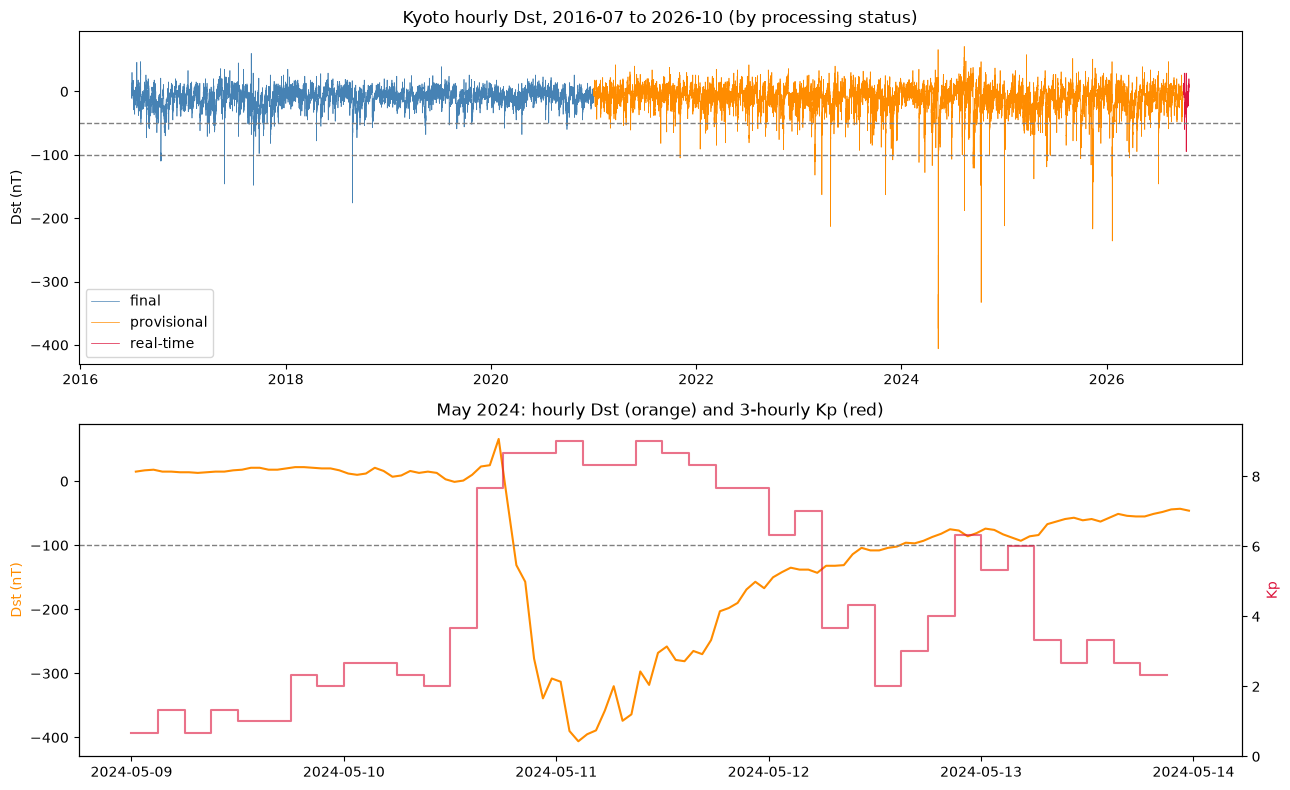

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

dt_naive = dst_raw["time"].dt.tz_localize(None)

# Panel 1: full window, coloured by processing status
for code, color, label in [(20, "steelblue", "final"), (10, "darkorange", "provisional"), (0, "crimson", "real-time")]:
    sel = dst_raw["version"] == code
    axes[0].plot(dt_naive[sel], dst_raw.loc[sel, "dst"], lw=0.5, color=color, label=label)
axes[0].axhline(-50, color="gray", ls="--", lw=1)
axes[0].axhline(-100, color="gray", ls="--", lw=1)
axes[0].set_title("Kyoto hourly Dst, 2016-07 to 2026-10 (by processing status)")
axes[0].set_ylabel("Dst (nT)")
axes[0].legend(loc="lower left")

# Panel 2: May 2024 storm, Dst with Kp on a second axis
w = dst_raw[dst_raw["time"].between("2024-05-09", "2024-05-14")]
axes[1].plot(dt_naive[w.index], w["dst"], color="darkorange")
axes[1].axhline(-100, color="gray", ls="--", lw=1)
axes[1].set_ylabel("Dst (nT)", color="darkorange")
ax2 = axes[1].twinx()
ax2.step(t3h, kp3h, where="post", color="crimson", alpha=0.6)
ax2.set_ylabel("Kp", color="crimson")
ax2.set_ylim(0, 9.5)
axes[1].set_title("May 2024: hourly Dst (orange) and 3-hourly Kp (red)")

plt.tight_layout()
plt.show()

### Kyoto Dst audit findings

- Source: WDC for Geomagnetism, Kyoto, HAPI `hour_dst` (best available), downloaded 2026-10-20. 11 yearly CSVs, no header row; columns: time, Dst (nT), version code.
- 90,327 hourly rows, 2016-07-01 00:29:30 to 2026-10-20 14:29:30 UTC. No duplicates, no missing hours, no 99999 fill values.
- Timestamps are UTC and sit at the bin centre (HH:29:30); each value is the mean of that hour. Must be handled when aligning with DSCOVR 1-minute data.
- Processing status (version code): 20 final = 2016-07-01 to 2020-12-31; 10 provisional = 2021-01-01 to 2026-09-30; 0 real-time = 2026-10-01 onward. **May 2024 storm is provisional** and may be revised by Kyoto: a stated limitation.
- Range: -406 nT (2024-05-11 02:29 UTC) to +71 nT. Hours <= -50: 2,570; <= -100: 363; <= -250: 30.
- Agreement with GFZ Kp: daily min Dst vs daily max Kp correlation -0.72. 8 of the 10 lowest-Dst days have Kp max >= 8.
- 49 days with Dst <= -100; 42 have Kp max >= 6. The other 7 are borderline (-100 to -103, one hour) or recovery-phase days (e.g. 2025-01-02, the day after a Kp 8 storm). Physical, not data errors.
- Design implication: define events from Dst, with a window that includes the recovery phase; do not use calendar days or Kp alone.
- Decision: use Kyoto Dst as the primary Dst; keep OMNI Dst as cross-check; carry the version code as a quality flag.

# NASA OMNI Data Audit

Load the NASA OMNI hourly files, using all 55 column names.

In [18]:
omni_cols = [
    "year", "doy", "hour", "bsr", "id_imf", "id_sw", "n_imf", "n_plasma",
    "B", "B_vec", "B_lat", "B_lon", "Bx_gse", "By_gse", "Bz_gse", "By_gsm", "Bz_gsm",
    "sig_B", "sig_Bvec", "sig_Bx", "sig_By", "sig_Bz",
    "T", "N", "V", "flow_lon", "flow_lat", "NaNp", "P_flow",
    "sig_T", "sig_N", "sig_V", "sig_phi", "sig_theta", "sig_NaNp",
    "E_field", "beta", "Mach_A",
    "Kp", "R", "Dst", "AE",
    "pf1", "pf2", "pf4", "pf10", "pf30", "pf60", "pf_flag",
    "ap", "f107", "PCN", "AL", "AU", "Mach_ms",
]
print("number of column names:", len(omni_cols))

omni_files = sorted((RAW / "dst").glob("omni2_hourly_20*.dat"))
print("files:", [f.name for f in omni_files])

omni_raw = pd.concat(
    [pd.read_csv(f, sep=r"\s+", header=None, names=omni_cols) for f in omni_files],
    ignore_index=True,
)

omni_raw["time"] = (
    pd.to_datetime(omni_raw["year"].astype(str), format="%Y")
    + pd.to_timedelta(omni_raw["doy"] - 1, unit="D")
    + pd.to_timedelta(omni_raw["hour"], unit="h")
)

print()
print("shape:", omni_raw.shape)
print("first / last time:", omni_raw["time"].min(), "/", omni_raw["time"].max())
print("duplicates:", omni_raw["time"].duplicated().sum())
print()
print(omni_raw.loc[omni_raw["time"].between("2024-05-11 00:00", "2024-05-11 05:00"),
                   ["time", "B", "Bz_gsm", "V", "N", "Kp", "Dst", "ap", "f107"]])

number of column names: 55
files: ['omni2_hourly_2016.dat', 'omni2_hourly_2017.dat', 'omni2_hourly_2018.dat', 'omni2_hourly_2019.dat', 'omni2_hourly_2020.dat', 'omni2_hourly_2021.dat', 'omni2_hourly_2022.dat', 'omni2_hourly_2023.dat', 'omni2_hourly_2024.dat', 'omni2_hourly_2025.dat', 'omni2_hourly_2026.dat']

shape: (96432, 56)
first / last time: 2016-01-01 00:00:00 / 2026-12-31 23:00:00
duplicates: 0

                     time     B  Bz_gsm      V     N  Kp  Dst   ap   f107
73272 2024-05-11 00:00:00  54.3   -35.3  742.0  14.7  90 -313  400  218.0
73273 2024-05-11 01:00:00  49.5   -34.0  732.0  25.2  90 -390  400  218.0
73274 2024-05-11 02:00:00  30.7   -20.5  738.0  38.4  90 -406  400  218.0
73275 2024-05-11 03:00:00  34.7   -22.8  748.0  17.5  83 -395  236  218.0
73276 2024-05-11 04:00:00  39.6   -18.9  704.0   8.4  83 -389  236  218.0
73277 2024-05-11 05:00:00  38.5     5.9  700.0  19.9  83 -358  236  218.0


Turn OMNI's fill values into NaN and see how much data is missing, per column and per year.

In [19]:
fills = {
    "B": 999.9, "Bz_gsm": 999.9, "V": 9999.0, "N": 999.9, "T": 9999999.0,
    "Kp": 99, "Dst": 99999, "ap": 999, "f107": 999.9,
}

omni = omni_raw[(omni_raw["time"] >= "2016-07-01") & (omni_raw["time"] <= "2026-10-20 23:00")].copy()
for col, fv in fills.items():
    omni[col] = omni[col].where(omni[col] != fv, np.nan)

print("rows in window:", len(omni))
print()
miss = omni[list(fills)].isna().sum().to_frame("missing")
miss["pct"] = (miss["missing"] / len(omni) * 100).round(2)
print(miss)

print()
print("missing % per year:")
by_year = omni.groupby(omni["time"].dt.year)[list(fills)].apply(lambda g: (g.isna().mean() * 100).round(1))
print(by_year)

print()
print("last valid timestamp per column:")
print({c: str(omni.loc[omni[c].notna(), "time"].max()) for c in fills})

rows in window: 90336

        missing   pct
B          1183  1.31
Bz_gsm     1209  1.34
V          1238  1.37
N          1338  1.48
T          1276  1.41
Kp          120  0.13
Dst         105  0.12
ap          120  0.13
f107        144  0.16

missing % per year:
         B  Bz_gsm    V    N    T   Kp  Dst   ap  f107
time                                                  
2016   0.0     0.0  0.0  0.3  0.0  0.0  0.0  0.0   0.0
2017   0.1     0.4  0.1  0.1  0.1  0.0  0.0  0.0   0.0
2018   0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0
2019   0.0     0.0  0.0  0.6  0.0  0.0  0.0  0.0   0.0
2020   0.0     0.0  0.0  0.1  0.0  0.0  0.0  0.0   0.0
2021   2.5     2.5  2.4  2.7  2.4  0.0  0.0  0.0   0.3
2022   0.0     0.0  0.4  0.4  0.5  0.0  0.0  0.0   0.0
2023   0.5     0.5  2.2  2.2  2.3  0.0  0.0  0.0   0.0
2024   0.4     0.4  2.3  2.3  2.4  0.0  0.0  0.0   0.0
2025   0.5     0.5  0.7  0.7  0.8  0.0  0.0  0.0   0.0
2026  11.8    11.8  7.5  7.5  7.5  1.7  1.5  1.7   1.7

last valid timestamp

Compare OMNI's Dst with Kyoto's, hour by hour.

In [20]:
ky = dst_raw.copy()
ky["hour_start"] = ky["time"].dt.tz_localize(None).dt.floor("h")
ky = ky.set_index("hour_start")[["dst", "version"]]

om = omni.set_index("time")["Dst"]

both = ky.index.intersection(om.index)
cmp_ = pd.DataFrame({"kyoto": ky.loc[both, "dst"], "omni": om.loc[both], "version": ky.loc[both, "version"]}).dropna()
cmp_["diff"] = cmp_["omni"] - cmp_["kyoto"]

print("hours compared:", len(cmp_))
print("identical hours:", (cmp_["diff"] == 0).sum(), f"({(cmp_['diff'] == 0).mean() * 100:.2f}%)")
print("max |diff|:", cmp_["diff"].abs().max())
print()
print("differing hours by Kyoto version code:")
print(cmp_.groupby("version")["diff"].agg(n="count", differing=lambda s: (s != 0).sum(), max_abs=lambda s: s.abs().max()))

print()
print("largest 8 differences:")
print(cmp_.reindex(cmp_["diff"].abs().sort_values(ascending=False).index).head(8))

hours compared: 90231
identical hours: 90229 (100.00%)
max |diff|: 2.0

differing hours by Kyoto version code:
             n  differing  max_abs
version                           
0          375          0      0.0
10       50376          2      2.0
20       39480          0      0.0

largest 8 differences:
                     kyoto  omni  version  diff
2026-08-25 21:00:00     -1   1.0       10   2.0
2026-08-25 20:00:00     -3  -2.0       10   1.0
2016-07-01 00:00:00     -1  -1.0       20   0.0
2023-05-12 06:00:00      3   3.0       10   0.0
2023-05-12 14:00:00     16  16.0       10   0.0
2023-05-12 13:00:00     19  19.0       10   0.0
2023-05-12 12:00:00     12  12.0       10   0.0
2023-05-12 11:00:00     14  14.0       10   0.0


Compare OMNI's Kp, ap and F10.7 with GFZ and CelesTrak.

In [21]:
o = omni[(omni["time"] >= "2016-07-26")].dropna(subset=["Kp"]).copy()
o["date"] = o["time"].dt.normalize()
slot = (o["time"].dt.hour // 3).to_numpy()          # 0..7
rows = np.arange(len(o))

g = win.set_index("date")
o["gfz_kp"] = g[kp_cols].reindex(o["date"]).to_numpy()[rows, slot]
o["gfz_ap"] = g[ap_cols].reindex(o["date"]).to_numpy()[rows, slot]

kd = (o["Kp"] / 10 - o["gfz_kp"]).abs()
print("hours compared:", len(o))
print("Kp: max abs diff (Kp units):", round(kd.max(), 3), "| hours > 0.05:", (kd > 0.05).sum())

ad = (o["ap"] - o["gfz_ap"]).abs()
print("ap: max abs diff:", ad.max(), "| hours differing:", (ad > 0).sum())

# F10.7 against CelesTrak (observed or interpolated rows), daily
o["ct_f107"] = ct_i["F10.7_OBS"].reindex(o["date"]).to_numpy()
fo = o.dropna(subset=["f107", "ct_f107"])
fd2 = (fo["f107"] - fo["ct_f107"]).abs()
print()
print("F10.7 hours compared:", len(fo), "| hours differing > 0.1:", (fd2 > 0.1).sum(), "| max diff:", round(fd2.max(), 2))
print("days differing > 0.1:", fo.loc[fd2 > 0.1, "date"].nunique())

print()
print("OMNI F10.7 on the 9 days GFZ left missing:")
gap_days = pd.to_datetime(["2020-10-23", "2020-12-17", "2020-12-18", "2021-05-09", "2021-06-16", "2024-08-26", "2025-02-12", "2025-02-17", "2026-05-09"])
print(o[o["date"].isin(gap_days)].groupby("date")[["f107", "ct_f107"]].agg(["mean", "count"]).round(1))

hours compared: 89616
Kp: max abs diff (Kp units): 0.033 | hours > 0.05: 0
ap: max abs diff: 0.0 | hours differing: 0

F10.7 hours compared: 89592 | hours differing > 0.1: 87456 | max diff: 12.2
days differing > 0.1: 3644

OMNI F10.7 on the 9 days GFZ left missing:
             f107       ct_f107      
             mean count    mean count
date                                 
2020-10-23   71.0    24    73.5    24
2020-12-17   79.1    24    81.8    24
2020-12-18   77.9    24    81.8    24
2021-05-09    NaN     0    76.2    24
2021-06-16   79.6    24    80.3    24
2024-08-26  234.3    24   227.0    24
2025-02-12  164.2    24   163.4    24
2025-02-17  179.4    24   181.8    24
2026-05-09  123.8    24   122.6    24


Check whether OMNI's F10.7 is the adjusted value by comparing it with the adjusted columns.

In [22]:
o["ct_adj"] = ct_i["F10.7_ADJ"].reindex(o["date"]).to_numpy()
o["gfz_adj"] = g["F107adj"].replace(-1, np.nan).reindex(o["date"]).to_numpy()

for name, col in [("CelesTrak ADJ", "ct_adj"), ("GFZ F10.7adj", "gfz_adj")]:
    fo = o.dropna(subset=["f107", col])
    d_ = (fo["f107"] - fo[col]).abs()
    print(f"{name:14s}: hours compared {len(fo)} | hours > 0.1: {(d_ > 0.1).sum()} | days > 0.1: {fo.loc[d_ > 0.1, 'date'].nunique()} | max diff {d_.max():.2f}")

print()
print("days where OMNI differs from CelesTrak ADJ by > 0.1 (one row per day):")
day = o.groupby("date")[["f107", "ct_adj", "gfz_adj"]].mean()
day["omni_minus_ct"] = (day["f107"] - day["ct_adj"]).round(2)
print(day[day["omni_minus_ct"].abs() > 0.1].round(1).head(15))

print()
print("the 9 GFZ-gap days, OMNI against CelesTrak ADJ:")
print(day.loc[gap_days.intersection(day.index)].round(1))

CelesTrak ADJ : hours compared 89592 | hours > 0.1: 1824 | days > 0.1: 76 | max diff 11.20
GFZ F10.7adj  : hours compared 89400 | hours > 0.1: 1272 | days > 0.1: 53 | max diff 11.20

days where OMNI differs from CelesTrak ADJ by > 0.1 (one row per day):
            f107  ct_adj  gfz_adj  omni_minus_ct
date                                            
2018-02-06  74.6    74.8     74.8           -0.2
2018-02-20  66.3    68.9     66.3           -2.6
2018-02-21  68.7    66.1     66.1            2.6
2018-02-22  67.0    68.2     67.0           -1.2
2018-02-23  66.2    68.5     66.2           -2.3
2018-02-24  66.8    68.6     66.8           -1.8
2018-02-25  65.9    67.8     65.9           -1.9
2018-02-26  68.4    70.6     68.4           -2.2
2018-02-27  66.6    68.7     66.6           -2.1
2018-02-28  67.5    68.6     67.5           -1.1
2019-02-06  67.9    69.3     67.9           -1.4
2019-02-08  68.1    69.8     68.1           -1.7
2019-12-20  69.7    67.7     67.7            2.0
2020-05-14 

### NASA OMNI audit findings

- Source: NASA OMNIWeb OMNI2 hourly, 11 yearly fixed-width files (55 columns, no header), downloaded 2026-10-20. Format per `omni2_format_description.txt`.
- Files are padded to a full calendar year with fill values (999.9, 9999., 99999, etc., per field). Converted to NaN for the columns used. Hour label = start of the hour (confirmed: Dst -406 at 02:00 matches Kyoto's 02:29:30 bin).
- Window used: 2016-07-01 to 2026-10-20, 90,336 hourly rows.
- Missing data: Kp/ap/f107 0.13-0.16%, Dst 0.12% (all trailing); B/Bz ~1.3%, V/N/T ~1.4-1.5%. Scattered gaps are small (plasma worse than field in 2021, 2023, 2024: ~2.2-2.4%). 2026 gaps are trailing lag: B ends 2026-09-30, plasma 2026-10-13, Kp/ap/f107 2026-10-15, Dst 2026-10-16 14:00.
- Dst: matches Kyoto on 90,229 of 90,231 hours; 2 provisional hours (2026-08-25) differ by 1-2 nT, cause not confirmed. May 2024 identical. OMNI Dst is copied from Kyoto, so agreement validates download/parsing, not Kyoto's accuracy.
- Kp (x10) and ap: match GFZ in all 89,616 compared hours (Kp max diff 0.033 = rounding).
- F10.7: OMNI `f107` is the adjusted (1 AU) value. Against CelesTrak ADJ, 76 days differ by > 0.1 (max 11.2); against GFZ F10.7adj, 53 days. OMNI matches GFZ on most of the Feb 2018 cluster where CelesTrak and GFZ disagree; source independence unknown. OMNI also differs from both sources on some days (e.g. 2018-02-21, 2019-12-20).
- OMNI fills 8 of the 9 GFZ F10.7 gap days with values that differ from CelesTrak's interpolation by 0.1-4.9 sfu; 2021-05-09 left empty. Gap-day values are uncertain in every source.
- Role in project: cross-check only (Dst, Kp, ap, F10.7 and, later, solar wind/IMF against DSCOVR). Not used to build the final dataset.
- Decision: F10.7 = CelesTrak `F10.7_ADJ`, with a flag for the 9 interpolated days; GFZ F10.7adj and OMNI as cross-checks.

# DSCOVR Magnetometer Data Audit

Write a function that reads one DSCOVR magnetometer file, and try it on 11 May 2024.

In [23]:
import gzip, shutil, tempfile
import xarray as xr

def read_nc_gz(path):
    """Read one gzipped DSCOVR NetCDF file into a DataFrame (time in UTC)."""
    with tempfile.TemporaryDirectory() as tmp:
        out = Path(tmp) / "x.nc"
        with gzip.open(path, "rb") as a, open(out, "wb") as b:
            shutil.copyfileobj(a, b)
        with xr.open_dataset(out, decode_times=False) as ds:
            df = ds.to_dataframe().reset_index()
            attrs = dict(ds.attrs)
    df["time"] = pd.to_datetime(df["time"], unit="ms")
    return df, attrs

f = next((RAW / "dscovr" / "m1m" / "2024" / "05").glob("*s20240511*"))
print("file:", f.name)

mag1, attrs1 = read_nc_gz(f)
print("shape:", mag1.shape)
print("time range:", mag1["time"].min(), "to", mag1["time"].max())
print("records_present / fill / missing:", attrs1["records_present"], attrs1["records_fill"], attrs1["records_missing"])
print()
print(list(mag1.columns))
print()
print(mag1[["bt", "bx_gsm", "by_gsm", "bz_gsm"]].describe().round(1).loc[["count", "min", "max"]])
print()
flag_cols = [c for c in mag1.columns if c.endswith("_flag")] + ["overall_quality"]
print("flag counts (sum of 1s; overall_quality shown as value counts):")
print(mag1[flag_cols[:-1]].sum().to_dict())
print(mag1["overall_quality"].value_counts().to_dict())

file: oe_m1m_dscovr_s20240511000000_e20240511235959_p20240512021629_pub.nc.gz
shape: (1440, 24)
time range: 2024-05-11 00:00:00 to 2024-05-11 23:59:00
records_present / fill / missing: 1440 0 0

['time', 'sample_count', 'measurement_mode', 'measurement_range', 'bt', 'bx_gse', 'by_gse', 'bz_gse', 'theta_gse', 'phi_gse', 'bx_gsm', 'by_gsm', 'bz_gsm', 'theta_gsm', 'phi_gsm', 'backfill_flag', 'future_packet_time_flag', 'old_packet_time_flag', 'fill_flag', 'possible_saturation_flag', 'calibration_mode_flag', 'maneuver_flag', 'low_sample_count_flag', 'overall_quality']

           bt  bx_gsm  by_gsm  bz_gsm
count  1440.0  1440.0  1440.0  1440.0
min       2.8   -34.3   -46.3   -50.4
max      55.9    18.0    41.8    24.5

flag counts (sum of 1s; overall_quality shown as value counts):
{'backfill_flag': 0, 'future_packet_time_flag': 0, 'old_packet_time_flag': 18, 'fill_flag': 0, 'possible_saturation_flag': 0, 'calibration_mode_flag': 0, 'maneuver_flag': 0, 'low_sample_count_flag': 0}
{0: 1440}


Load every magnetometer file (keeping the latest version of each day) and save the result as a parquet file.

In [24]:
import re
from tqdm.auto import tqdm

INTERIM = Path("../data/interim")

files = sorted((RAW / "dscovr" / "m1m").glob("*/*/*.nc.gz"))
tbl = pd.DataFrame({"path": files})
tbl["day"] = tbl["path"].map(lambda p: re.search(r"_s(\d{8})", p.name).group(1))
tbl["proc"] = tbl["path"].map(lambda p: re.search(r"_p(\d{14})", p.name).group(1))

# several days have reprocessed versions: keep the latest processing stamp
latest = tbl.sort_values("proc").groupby("day").tail(1).sort_values("day")
print("files:", len(tbl), "| unique days:", len(latest), "| older versions dropped:", len(tbl) - len(latest))

keep = ["time", "sample_count", "measurement_mode", "measurement_range",
        "bt", "bx_gsm", "by_gsm", "bz_gsm",
        "backfill_flag", "future_packet_time_flag", "old_packet_time_flag", "fill_flag",
        "possible_saturation_flag", "calibration_mode_flag", "maneuver_flag",
        "low_sample_count_flag", "overall_quality"]

parts, failed = [], []
for p in tqdm(latest["path"]):
    try:
        df, _ = read_nc_gz(p)
        parts.append(df[keep])
    except Exception as e:
        failed.append((p.name, str(e)))

mag = pd.concat(parts, ignore_index=True)
for c in ["bt", "bx_gsm", "by_gsm", "bz_gsm"]:
    mag[c] = mag[c].astype("float32")

print()
print("failed files:", len(failed))
print("shape:", mag.shape)
print("time range:", mag["time"].min(), "to", mag["time"].max())
print("duplicate timestamps:", mag["time"].duplicated().sum())
print("memory (MB):", round(mag.memory_usage(deep=True).sum() / 1e6))

mag.to_parquet(INTERIM / "dscovr_mag_1min_all.parquet")
print("saved to data/interim/dscovr_mag_1min_all.parquet")

/Users/manasstark/Projects/Spaceweather_GENAI_RAG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


files: 3645 | unique days: 3575 | older versions dropped: 70


100%|███████████████████████████████████████| 3575/3575 [00:19<00:00, 180.90it/s]



failed files: 0
shape: (5148000, 17)
time range: 2016-07-26 00:00:00 to 2026-06-29 23:59:00
duplicate timestamps: 0
memory (MB): 190
saved to data/interim/dscovr_mag_1min_all.parquet


Count the missing minutes and the quality flags in the magnetometer data.

In [25]:
vals = ["bt", "bx_gsm", "by_gsm", "bz_gsm"]
flags = [c for c in mag.columns if c.endswith("_flag")]

na = mag[vals].isna().sum().to_frame("nan_minutes")
na["pct"] = (na["nan_minutes"] / len(mag) * 100).round(2)
print(na)

print()
print("fill_flag == 1          :", (mag["fill_flag"] == 1).sum())
print("bz NaN and fill_flag==1 :", (mag["bz_gsm"].isna() & (mag["fill_flag"] == 1)).sum())
print("bz NaN but fill_flag==0 :", (mag["bz_gsm"].isna() & (mag["fill_flag"] == 0)).sum())
print("fill_flag==1 but bz present:", (mag["bz_gsm"].notna() & (mag["fill_flag"] == 1)).sum())

print()
print("flag counts (minutes with flag = 1):")
print(mag[flags].sum().to_string())

print()
print("overall_quality value counts:")
print(mag["overall_quality"].value_counts().sort_index())

print()
print("overall_quality vs 'any individual flag set':")
print(pd.crosstab(mag["overall_quality"], mag[flags].any(axis=1), rownames=["overall_quality"], colnames=["any_flag"]))

print()
print("bz_gsm NaN % per year:")
print(mag.groupby(mag["time"].dt.year)["bz_gsm"].apply(lambda s: round(s.isna().mean() * 100, 2)).to_string())

        nan_minutes    pct
bt           570455  11.08
bx_gsm       570455  11.08
by_gsm       570455  11.08
bz_gsm       570455  11.08

fill_flag == 1          : 570455
bz NaN and fill_flag==1 : 570455
bz NaN but fill_flag==0 : 0
fill_flag==1 but bz present: 0

flag counts (minutes with flag = 1):
backfill_flag                 2557
future_packet_time_flag          0
old_packet_time_flag        163573
fill_flag                   570455
possible_saturation_flag         1
calibration_mode_flag            0
maneuver_flag                15583
low_sample_count_flag       570479

overall_quality value counts:
overall_quality
0    5147689
1        311
Name: count, dtype: int64

overall_quality vs 'any individual flag set':
any_flag           False   True 
overall_quality                 
0                4398622  749067
1                      0     311

bz_gsm NaN % per year:
time
2016     1.18
2017     1.10
2018     2.80
2019    49.93
2020    17.58
2021     2.30
2022     2.49
2023     2.02
20

Work out where the gaps are, by month and by gap length.

In [26]:
full_idx = pd.date_range(mag["time"].min(), mag["time"].max(), freq="min")
s = mag.set_index("time")["bz_gsm"].reindex(full_idx)      # absent days become NaN too
isna = s.isna().to_numpy()

print("minutes in range:", len(full_idx), "| NaN incl. absent days:", int(isna.sum()), f"({isna.mean() * 100:.2f}%)")

# NaN % per year x month
tab = s.isna().groupby([full_idx.year, full_idx.month]).mean().mul(100).round(0).unstack()
print()
print("bz NaN % by year (rows) and month (columns):")
print(tab.fillna(-1).astype(int).to_string())

# gap run lengths
e = np.diff(np.r_[0, isna.astype(np.int8), 0])
starts, ends = np.flatnonzero(e == 1), np.flatnonzero(e == -1)
gaps = pd.DataFrame({"start": full_idx[starts], "end": full_idx[ends - 1], "minutes": ends - starts})
gaps["bucket"] = pd.cut(gaps["minutes"], [0, 5, 60, 1440, 10**9], labels=["<=5 min", "6-60 min", "1-24 h", ">24 h"])

print()
print("gaps by length:")
print(gaps.groupby("bucket", observed=True).agg(n=("minutes", "size"), total_minutes=("minutes", "sum")))
print()
print("10 longest gaps:")
print(gaps.sort_values("minutes", ascending=False).head(10).to_string(index=False))

minutes in range: 5221440 | NaN incl. absent days: 643895 (12.33%)

bz NaN % by year (rows) and month (columns):
      1   2   3   4   5   6    7    8    9   10   11  12
2016  -1  -1  -1  -1  -1  -1    0    1    1   2    1   1
2017   2   1   5   0   4   2    2    1    0   0    1   2
2018   6   2   3   0   1   0    1    2    1   9    1   7
2019  12   5   0   1   0  11  100  100   90  88  100  88
2020  99  82   3   1   1   6    3    0    0   1    4  14
2021  11   1   0   1   0   0    3    3    1   1    1   6
2022  10   1   1   5   1   3    1    1    1   1    3   4
2023  11   3   0   0   0   0    1    1    1   1    1   5
2024  10  11   3   1   1   5    0    2    6  10    4  14
2025  12   4   2   0   1   1   53  100  100  23   21  41
2026  42  22  14   7   3   4   -1   -1   -1  -1   -1  -1

gaps by length:
             n  total_minutes
bucket                       
<=5 min   4791           9182
6-60 min  1373          30920
1-24 h     900         181884
>24 h       19         421909

10 lo

Check how much magnetometer data exists on the days of the strongest storms.

In [27]:
cover = s.notna().groupby(full_idx.normalize()).mean().mul(100).round(1).rename("bz_present_pct")

top = dk.sort_values("dst_min").head(15).join(cover, how="left")
top["bz_present_pct"] = top["bz_present_pct"].fillna(0)   # absent days = 0 % present
print("15 lowest-Dst days and DSCOVR Bz coverage on that day:")
print(top)

print()
print("storm days (Dst min <= -100) by DSCOVR coverage on the day:")
st = dk[dk["dst_min"] <= -100].join(cover, how="left")
st["bz_present_pct"] = st["bz_present_pct"].fillna(0)
print("  storm days:", len(st))
print("  coverage >= 90%:", (st["bz_present_pct"] >= 90).sum())
print("  coverage 50-90%:", ((st["bz_present_pct"] >= 50) & (st["bz_present_pct"] < 90)).sum())
print("  coverage < 50% :", (st["bz_present_pct"] < 50).sum())
print()
print("storm days with < 50% coverage:")
print(st[st["bz_present_pct"] < 50])

15 lowest-Dst days and DSCOVR Bz coverage on that day:
            dst_min  kp_max  bz_present_pct
2024-05-11     -406   9.000           100.0
2024-05-10     -339   8.667            99.8
2024-10-11     -333   8.333            88.5
2024-10-10     -303   8.667            88.5
2026-01-20     -236   7.667            79.2
2025-11-12     -217   8.667            89.9
2023-04-24     -213   8.000           100.0
2025-01-01     -212   8.000            82.3
2024-08-12     -188   8.000           100.0
2018-08-26     -176   7.333           100.0
2026-01-21     -167   7.333            74.5
2023-04-23     -165   8.333            99.9
2023-11-05     -163   7.333            99.9
2023-03-24     -163   8.000            99.6
2024-05-12     -150   7.000           100.0

storm days (Dst min <= -100) by DSCOVR coverage on the day:
  storm days: 49
  coverage >= 90%: 35
  coverage 50-90%: 12
  coverage < 50% : 2

storm days with < 50% coverage:
            dst_min  kp_max  bz_present_pct
2025-09-30     -106  

Check the magnetometer values are physically sensible and whether the flagged minutes look any different.

In [28]:
v = mag.dropna(subset=["bz_gsm"]).copy()

print(v[vals].describe().round(2).loc[["count", "min", "max", "mean", "std"]])

print()
print("bt < 0                  :", (v["bt"] < 0).sum())
print("bt > 100 nT             :", (v["bt"] > 100).sum())
print("any |component| > 100 nT:", (v[["bx_gsm", "by_gsm", "bz_gsm"]].abs() > 100).any(axis=1).sum())

calc = np.sqrt(v["bx_gsm"] ** 2 + v["by_gsm"] ** 2 + v["bz_gsm"] ** 2)
print("max |bt - sqrt(bx2+by2+bz2)| (nT):", round(float((v["bt"] - calc).abs().max()), 3))

v["extreme"] = (v["bz_gsm"].abs() > 20) | (v["bt"] > 40)
rows = []
for fl in ["old_packet_time_flag", "maneuver_flag", "backfill_flag", "possible_saturation_flag", "low_sample_count_flag"]:
    m = v[fl] == 1
    rows.append({"flag": fl, "minutes_with_data": int(m.sum()),
                 "pct_extreme": round(v.loc[m, "extreme"].mean() * 100, 2) if m.any() else np.nan})
none = v[flags].sum(axis=1) == 0
rows.append({"flag": "(no flag set)", "minutes_with_data": int(none.sum()),
             "pct_extreme": round(v.loc[none, "extreme"].mean() * 100, 2)})
print()
print(pd.DataFrame(rows).to_string(index=False))

print()
print("the one saturation minute:")
print(v.loc[v["possible_saturation_flag"] == 1, ["time", "bt", "bx_gsm", "by_gsm", "bz_gsm", "measurement_range"]])

               bt      bx_gsm      by_gsm      bz_gsm
count  4577545.00  4577545.00  4577545.00  4577545.00
min          0.12      -47.39      -79.89      -57.93
max         95.21       57.95       73.45       83.30
mean         5.85        0.09       -0.14       -0.08
std          3.16        3.77        4.13        3.52

bt < 0                  : 0
bt > 100 nT             : 0
any |component| > 100 nT: 0
max |bt - sqrt(bx2+by2+bz2)| (nT): 26.409

                    flag  minutes_with_data  pct_extreme
    old_packet_time_flag             163573         0.08
           maneuver_flag              15583         0.00
           backfill_flag               2557         0.00
possible_saturation_flag                  1         0.00
   low_sample_count_flag                 24         0.00
           (no flag set)            4398622         0.13

the one saturation minute:
                      time    bt  bx_gsm  by_gsm  bz_gsm  measurement_range
417078 2017-05-12 15:18:00  3.95    3.88   -0

Look at where the total field and its components disagree, and when the extreme values happen.

In [30]:
v["calc_b"] = calc
v["bt_diff"] = (v["bt"] - v["calc_b"])

print("|bt - vector magnitude| quantiles (nT):")
print(v["bt_diff"].abs().quantile([0.5, 0.9, 0.99, 0.999, 1.0]).round(3).to_string())
print()
for t in (1, 5, 10):
    print(f"minutes with |diff| > {t} nT:", int((v['bt_diff'].abs() > t).sum()))

print()
print("8 largest mismatches:")
print(v.loc[v["bt_diff"].abs().nlargest(8).index, ["time", "bt", "bx_gsm", "by_gsm", "bz_gsm", "calc_b", "bt_diff"]]
      .round({"bt": 2, "bx_gsm": 2, "by_gsm": 2, "bz_gsm": 2, "calc_b": 2, "bt_diff": 2})
      .to_string(index=False))

print()
print("when do the extremes occur?")
for col, fn in [("bt", "idxmax"), ("bz_gsm", "idxmax"), ("bz_gsm", "idxmin"), ("by_gsm", "idxmin")]:
    r = v.loc[getattr(v[col], fn)()]
    print(f"{col:7s} {fn[3:]}: {r[col]:7.2f} nT at {r['time']}  (bt {r['bt']:.1f}, flags old={r['old_packet_time_flag']}, maneuver={r['maneuver_flag']})")

|bt - vector magnitude| quantiles (nT):
0.500     0.012
0.900     0.083
0.990     0.500
0.999     1.725
1.000    26.409

minutes with |diff| > 1 nT: 14359
minutes with |diff| > 5 nT: 154
minutes with |diff| > 10 nT: 21

8 largest mismatches:
               time        bt     bx_gsm  by_gsm     bz_gsm    calc_b   bt_diff
2026-01-19 19:07:00 44.930000 -11.970000   14.08  -1.230000 18.520000 26.410000
2024-05-10 18:21:00 35.490002  -0.920000  -10.78  -8.180000 13.560000 21.930000
2025-11-12 02:37:00 28.370001  -4.060000   -6.50   0.410000  7.670000 20.700001
2026-01-19 20:46:00 29.500000  10.630000    3.85   1.700000 11.430000 18.070000
2026-01-19 19:03:00 50.759998 -15.910000   -4.59 -28.379999 32.860001 17.900000
2026-01-19 19:06:00 51.070000 -25.110001    3.55 -24.139999 35.009998 16.059999
2024-03-24 14:26:00 17.040001   1.410000    2.82   0.900000  3.280000 13.760000
2025-11-12 02:35:00 29.340000  -1.420000  -15.63   1.010000 15.730000 13.610000

when do the extremes occur?
bt      m

Plot Bz, the total field and Dst through the May 2024 storm.

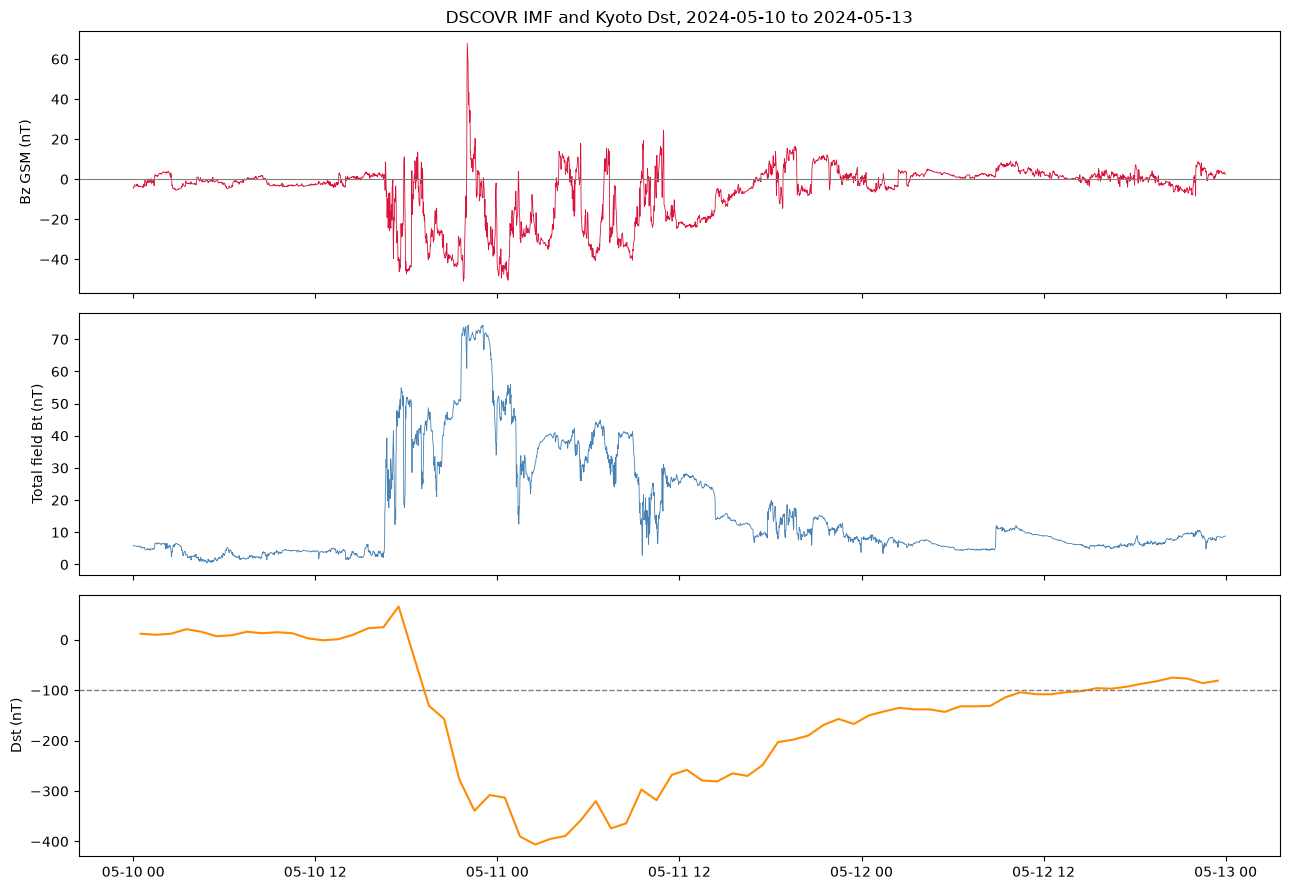

In [31]:
w = mag[(mag["time"] >= "2024-05-10") & (mag["time"] < "2024-05-13")]
dw = dst_raw[dst_raw["time"].between("2024-05-10", "2024-05-13")]

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

axes[0].plot(w["time"], w["bz_gsm"], lw=0.6, color="crimson")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Bz GSM (nT)")
axes[0].set_title("DSCOVR IMF and Kyoto Dst, 2024-05-10 to 2024-05-13")

axes[1].plot(w["time"], w["bt"], lw=0.6, color="steelblue")
axes[1].set_ylabel("Total field Bt (nT)")

axes[2].plot(dw["time"].dt.tz_localize(None), dw["dst"], color="darkorange")
axes[2].axhline(-100, color="gray", ls="--", lw=1)
axes[2].set_ylabel("Dst (nT)")

plt.tight_layout()
plt.show()

### DSCOVR magnetometer (m1m) audit findings

- Source: NOAA NCEI DSCOVR Level 2 magnetometer, 1-minute averages (Hodges-Lehmann M-estimator). 3,645 gzipped NetCDF files; latest processing version kept per day -> 3,575 unique days, 2016-07-26 to 2026-06-29. 5,148,000 minute rows (1,440 per file), no duplicate timestamps. Cached as `data/interim/dscovr_mag_1min_all.parquet`.
- Time stored as ms since 1970 UTC. Use GSM components (bx/by/bz_gsm).
- Missing: 51 whole days absent. Inside files, NaN = `fill_flag` = 1 exactly: 570,455 of 5,148,000 minutes (11.08%). Including absent days: 643,895 of 5,221,440 (12.33%).
- Gaps are mostly a few long outages: 19 gaps > 24 h hold 66% of missing minutes; gaps <= 1 h are only 6%. Main outages: 2019-06-27 to 2020-02-06 (Jul-Dec 2019 88-100% missing), 2025-07-15 to 2025-10-02 (79 days); early 2026 also poor (Jan 42%, Feb 22%, Mar 14%). Cause not in the files; not verified.
- Storm coverage: of 49 days with Dst <= -100, 35 have >= 90% Bz coverage, 12 partial, 2 below 50% (2025-09-30 inside the outage; 2026-07-04 after DSCOVR data end). May 2024 (99.8-100%), April 2023, Aug 2024 and Aug 2018 storm days are fully covered.
- Flags: `overall_quality` is uninformative (0 even on NaN rows; 1 on only 311 minutes). `low_sample_count_flag` = fill + 24 minutes. `old_packet_time_flag` 163,573 min; `maneuver_flag` 15,583; `backfill_flag` 2,557; `possible_saturation_flag` 1 (2017-05-12 15:18, a quiet minute). Flagged minutes are not richer in extreme values than unflagged ones.
- Values plausible: Bt 0.12-95.2 nT; Bz -57.9 to +83.3 nT. All four extremes fall in one storm interval, 2026-01-19 19:02-21:31 UTC.
- `bt` is not always the magnitude of the three components: median difference 0.012 nT, 99% < 0.5 nT, but 154 minutes > 5 nT, largest at shock/onset times (likely robust averaging of a fast-changing field; not proven). Use the components.
- May 2024: Bt jumps ~16:30 UTC 05-10 and peaks ~74 nT around 22-23 UT; Bz reaches ~-50 nT (with a ~+68 nT spike); Dst minimum -406 at 02:29 UTC 05-11; Dst stays below -100 until about the evening of 05-12.
- L1 to Earth delay is ~35-40 min at 700 km/s; to be handled at alignment.
- Proposed rule (to confirm at alignment): NaN/fill = missing; blank maneuver and saturation minutes; keep old_packet_time and backfill; use components not Bt.
- Open decision (user): whether to fill DSCOVR outages with OMNI solar wind/IMF (OMNI shows 0.0% B missing in 2019).

# DSCOVR Faraday Cup

Load one Faraday cup file (11 May 2024) to see how it's structured and which flags it has.

In [32]:
f = next((RAW / "dscovr" / "f1m" / "2024" / "05").glob("*s20240511*"))
print("file:", f.name)

fc1, fattrs1 = read_nc_gz(f)
print("shape:", fc1.shape)
print("time range:", fc1["time"].min(), "to", fc1["time"].max())
print("records_present / fill / missing:", fattrs1["records_present"], fattrs1["records_fill"], fattrs1["records_missing"])

core = ["proton_speed", "proton_density", "proton_temperature",
        "proton_vx_gsm", "proton_vy_gsm", "proton_vz_gsm",
        "alpha_speed", "alpha_density", "alpha_temperature"]
print()
print(fc1[core].describe().round(1).loc[["count", "min", "max"]].T)

fl = [c for c in fc1.columns if c.endswith("_flag")]
sums = fc1[fl].sum()
print()
print("flag columns:", len(fl))
print("flags set on this day (non-zero only):")
print(sums[sums > 0].to_string())

print()
print("overall_quality value counts:")
print(fc1["overall_quality"].value_counts().sort_index().to_dict())

file: oe_f1m_dscovr_s20240511000000_e20240511235959_p20240512022214_pub.nc.gz
shape: (1440, 84)
time range: 2024-05-11 00:00:00 to 2024-05-11 23:59:00
records_present / fill / missing: 1440 1 0

                     count     min        max
proton_speed        1439.0   355.0      826.2
proton_density      1439.0     0.1       53.3
proton_temperature  1439.0  2000.0  1342887.0
proton_vx_gsm       1439.0  -821.7     -355.0
proton_vy_gsm       1439.0   -94.6      139.5
proton_vz_gsm       1439.0  -103.4      118.6
alpha_speed            0.0     NaN        NaN
alpha_density          0.0     NaN        NaN
alpha_temperature      0.0     NaN        NaN

flag columns: 63
flags set on this day (non-zero only):
old_packet_time_flag             8
fill_flag                        1
proton_peak_unresolved_flag     66
proton_alpha_confusion_flag     54
proton_peak_unbounded_flag     293
reduced_proton_quality_flag    696
bad_proton_speed_flag           32
bad_proton_density_flag         32
bad_prot

Load every Faraday cup file (this version copes with the older files that are missing one column) and save them.

In [34]:
ffiles = sorted((RAW / "dscovr" / "f1m").glob("*/*/*.nc.gz"))
ftbl = pd.DataFrame({"path": ffiles})
ftbl["day"] = ftbl["path"].map(lambda p: re.search(r"_s(\d{8})", p.name).group(1))
ftbl["proc"] = ftbl["path"].map(lambda p: re.search(r"_p(\d{14})", p.name).group(1))
flatest = ftbl.sort_values("proc").groupby("day").tail(1).sort_values("day")
print("files:", len(ftbl), "| unique days:", len(flatest), "| older versions dropped:", len(ftbl) - len(flatest))

fkeep = ["time", "sample_count",
         "proton_speed", "proton_density", "proton_temperature",
         "proton_vx_gsm", "proton_vy_gsm", "proton_vz_gsm", "alpha_density",
         "backfill_flag", "old_packet_time_flag", "fill_flag", "normal_mode_flag",
         "proton_peak_unresolved_flag", "proton_alpha_confusion_flag", "proton_peak_unbounded_flag",
         "proton_peak_loss_flag", "large_flow_angle_flag", "possible_second_proton_peak_flag",
         "calibration_mode_flag", "maneuver_flag", "reduced_proton_quality_flag",
         "bad_proton_speed_flag", "bad_proton_density_flag", "bad_proton_temperature_flag",
         "low_proton_velocity_sample_count_flag", "overall_quality"]

parts, ffailed = [], []
for p in tqdm(flatest["path"]):
    try:
        df, _ = read_nc_gz(p)
        parts.append(df.reindex(columns=fkeep))
    except Exception as e:
        ffailed.append((p.name, str(e)))

fc = pd.concat(parts, ignore_index=True)
for c in ["proton_speed", "proton_density", "proton_temperature", "proton_vx_gsm", "proton_vy_gsm", "proton_vz_gsm", "alpha_density"]:
    fc[c] = fc[c].astype("float32")

print()
print("failed files:", len(ffailed))
print("shape:", fc.shape)
print("time range:", fc["time"].min(), "to", fc["time"].max())
print("duplicate timestamps:", fc["time"].duplicated().sum())

fc.to_parquet(INTERIM / "dscovr_fc_1min_all.parquet")
print("saved to data/interim/dscovr_fc_1min_all.parquet")

files: 3644 | unique days: 3575 | older versions dropped: 69


100%|████████████████████████████████████████| 3575/3575 [00:51<00:00, 69.12it/s]



failed files: 0
shape: (5148000, 27)
time range: 2016-07-26 00:00:00 to 2026-06-29 23:59:00
duplicate timestamps: 0
saved to data/interim/dscovr_fc_1min_all.parquet


Count the missing minutes, the flags and the out-of-range values in the Faraday cup data.

In [35]:
pv = ["proton_speed", "proton_density", "proton_temperature", "proton_vx_gsm", "proton_vy_gsm", "proton_vz_gsm"]
fflags = [c for c in fc.columns if c.endswith("_flag")]

na = fc[pv + ["alpha_density"]].isna().sum().to_frame("nan_minutes")
na["pct"] = (na["nan_minutes"] / len(fc) * 100).round(2)
print(na)

print()
print("fill_flag == 1               :", (fc["fill_flag"] == 1).sum())
print("speed NaN and fill_flag==1   :", (fc["proton_speed"].isna() & (fc["fill_flag"] == 1)).sum())
print("speed NaN but fill_flag==0   :", (fc["proton_speed"].isna() & (fc["fill_flag"] == 0)).sum())
print("fill_flag==1 but speed present:", (fc["proton_speed"].notna() & (fc["fill_flag"] == 1)).sum())

print()
print("flag counts (minutes with flag = 1):")
print(fc[fflags].sum().astype(int).to_string())

print()
print("overall_quality value counts:")
print(fc["overall_quality"].value_counts().sort_index().to_string())

yr = fc["time"].dt.year
tab = pd.DataFrame({
    "speed_nan_pct": fc.groupby(yr)["proton_speed"].apply(lambda s: round(s.isna().mean() * 100, 1)),
    "reduced_quality_pct": fc.groupby(yr)["reduced_proton_quality_flag"].apply(lambda s: round(s.mean() * 100, 1)),
})
print()
print(tab.to_string())

sp, de, te = fc["proton_speed"].dropna(), fc["proton_density"].dropna(), fc["proton_temperature"].dropna()
print()
print("speed  min/max:", round(float(sp.min()), 1), "/", round(float(sp.max()), 1), "| <189:", int((sp < 189).sum()), "| >1111:", int((sp > 1111).sum()))
print("density min/max:", round(float(de.min()), 2), "/", round(float(de.max()), 1), "| <1:", int((de < 1).sum()), "| >100:", int((de > 100).sum()))
print("temp   min/max:", round(float(te.min())), "/", round(float(te.max())), "| == 2000 exactly:", int((te == 2000).sum()), f"({(te == 2000).mean() * 100:.2f}%)")

                    nan_minutes     pct
proton_speed             624747   12.14
proton_density           624747   12.14
proton_temperature       624747   12.14
proton_vx_gsm            624747   12.14
proton_vy_gsm            624747   12.14
proton_vz_gsm            624747   12.14
alpha_density           5148000  100.00

fill_flag == 1               : 624747
speed NaN and fill_flag==1   : 624747
speed NaN but fill_flag==0   : 0
fill_flag==1 but speed present: 0

flag counts (minutes with flag = 1):
backfill_flag                                313
old_packet_time_flag                      121296
fill_flag                                 624747
normal_mode_flag                               8
proton_peak_unresolved_flag               211280
proton_alpha_confusion_flag               167216
proton_peak_unbounded_flag                496764
proton_peak_loss_flag                          0
large_flow_angle_flag                          0
possible_second_proton_peak_flag               0
calibrat

Compare DSCOVR's hourly speed with OMNI's, grouped by how many minutes were flagged.

In [36]:
ft = fc.set_index("time")
agg = ft[["proton_speed", "proton_density", "reduced_proton_quality_flag"]].resample("h").mean()
cnt = ft["proton_speed"].resample("h").count()
h = agg[cnt >= 45]                                  # hours with at least 45 valid minutes

j = h.join(omni.set_index("time")[["V", "N"]], how="inner").dropna(subset=["proton_speed", "V"])
j["dv"] = j["proton_speed"] - j["V"]
j["dn_ratio"] = j["proton_density"] / j["N"]
j["rq"] = pd.cut(j["reduced_proton_quality_flag"], [-0.01, 0.0, 0.5, 1.0],
                 labels=["none flagged", "some (<=50%)", "most (>50%)"])

print("hours compared:", len(j), "| corr(speed, OMNI V):", round(j["proton_speed"].corr(j["V"]), 3))
print()
print("DSCOVR minus OMNI speed (km/s) by share of minutes flagged reduced-quality:")
print(j.groupby("rq", observed=True)["dv"].agg(
    hours="count", mean="mean", median="median", std="std",
    abs_p95=lambda s: s.abs().quantile(0.95)).round(1))

print()
print("density ratio DSCOVR / OMNI by the same groups (median, IQR):")
print(j.groupby("rq", observed=True)["dn_ratio"].agg(
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)).round(2))

print()
print("hours in storm conditions (OMNI V > 700 km/s):", int((j['V'] > 700).sum()))
print(j.loc[j["V"] > 700].groupby("rq", observed=True)["dv"].agg(hours="count", mean="mean", std="std").round(1))

hours compared: 73981 | corr(speed, OMNI V): 0.882

DSCOVR minus OMNI speed (km/s) by share of minutes flagged reduced-quality:
              hours  mean  median   std  abs_p95
rq                                              
none flagged  32428   3.2     1.5  12.0     25.6
some (<=50%)  19833   8.8     7.9  22.6     38.5
most (>50%)   21720  12.4    13.0  80.0    177.2

density ratio DSCOVR / OMNI by the same groups (median, IQR):
              median   q25   q75
rq                              
none flagged    1.08  0.87  1.42
some (<=50%)    1.31  0.90  1.97
most (>50%)     1.50  0.75  2.60

hours in storm conditions (OMNI V > 700 km/s): 752
              hours   mean    std
rq                               
none flagged     21   -4.5   19.9
some (<=50%)    129   -2.6   29.9
most (>50%)     602 -239.5  135.2


Look at DSCOVR against OMNI speed hour by hour through the May 2024 storm.

In [37]:
m = j.loc["2024-05-10 12:00":"2024-05-12 12:00",
          ["proton_speed", "V", "dv", "reduced_proton_quality_flag"]].copy()
m.columns = ["dscovr_speed", "omni_V", "dscovr_minus_omni", "share_flagged"]
print(m.round(2).to_string())

print()
print("hours in table:", len(m), "| of 49 possible (some hours dropped for < 45 valid minutes)")
print("mean difference (km/s):", round(m["dscovr_minus_omni"].mean(), 1),
      "| hours with |diff| > 100 km/s:", int((m["dscovr_minus_omni"].abs() > 100).sum()))

                     dscovr_speed  omni_V  dscovr_minus_omni  share_flagged
time                                                                       
2024-05-10 12:00:00    444.779999   409.0              35.78           0.97
2024-05-10 13:00:00    463.760010   411.0              52.76           0.52
2024-05-10 14:00:00    457.959991   446.0              11.96           0.00
2024-05-10 15:00:00    448.809998   455.0              -6.19           0.00
2024-05-10 16:00:00    553.429993   449.0             104.43           0.20
2024-05-10 17:00:00    701.500000   571.0             130.50           0.20
2024-05-10 18:00:00    683.510010   697.0             -13.49           0.22
2024-05-10 19:00:00    695.909973   664.0              31.91           0.00
2024-05-10 20:00:00    688.690002   702.0             -13.31           0.00
2024-05-10 21:00:00    699.739990   697.0               2.74           0.10
2024-05-10 22:00:00    736.650024   729.0               7.65           0.00
2024-05-10 2

See how the speed error grows as more of the minutes in an hour are flagged.

In [38]:
bins = [-0.01, 0, 0.25, 0.5, 0.75, 0.999, 1.0]
labels = ["0%", "0-25%", "25-50%", "50-75%", "75-<100%", "100%"]
j["rq2"] = pd.cut(j["reduced_proton_quality_flag"], bins, labels=labels)

g = j.groupby("rq2", observed=True)["dv"]
res = pd.DataFrame({
    "hours": g.count(),
    "median_dv": g.median(),
    "std_dv": g.std(),
    "p95_abs": g.apply(lambda s: s.abs().quantile(0.95)),
    "pct_abs_over_100": g.apply(lambda s: (s.abs() > 100).mean() * 100),
}).round(1)
print(res)

full = j[j["reduced_proton_quality_flag"] >= 0.999]
print()
print("hours with 100% of minutes flagged:", len(full))
print("OMNI V median in those hours:", full["V"].median(), "| share with OMNI V > 600:", round((full["V"] > 600).mean(), 2))
print("by year:", full.groupby(full.index.year).size().to_dict())
print()
print("DSCOVR speed in 100%-flagged hours when OMNI V > 700:")
print(full.loc[full["V"] > 700, "proton_speed"].describe().round(0).to_string())

          hours  median_dv  std_dv  p95_abs  pct_abs_over_100
rq2                                                          
0%        32428        1.5    12.0     25.6               0.0
0-25%     14101        7.3    19.2     35.5               0.2
25-50%     5732       10.0    29.1     44.4               0.6
50-75%     4897       11.2    39.6     54.2               1.4
75-<100%   7239       12.0    59.3    124.4               7.2
100%       9584       16.8   105.1    228.0              25.5

hours with 100% of minutes flagged: 9584
OMNI V median in those hours: 438.0 | share with OMNI V > 600: 0.16
by year: {2016: 110, 2017: 341, 2018: 188, 2019: 91, 2020: 384, 2021: 250, 2022: 1009, 2023: 2643, 2024: 2440, 2025: 1454, 2026: 674}

DSCOVR speed in 100%-flagged hours when OMNI V > 700:
count    471.0
mean     485.0
std       50.0
min      246.0
25%      465.0
50%      483.0
75%      498.0
max      702.0


Plot DSCOVR and OMNI speed for May 2024, with the share of flagged minutes underneath.

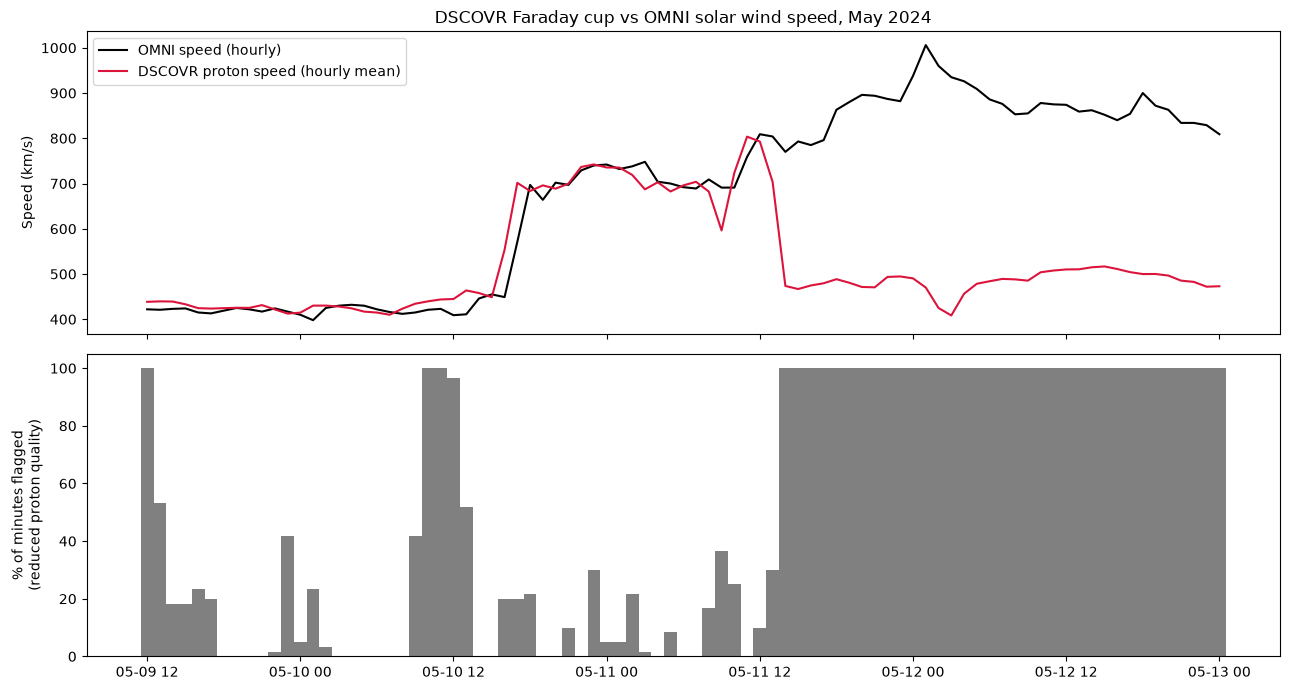

In [39]:
w = j.loc["2024-05-09 12:00":"2024-05-13 00:00"]

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(w.index, w["V"], color="black", label="OMNI speed (hourly)")
ax[0].plot(w.index, w["proton_speed"], color="crimson", label="DSCOVR proton speed (hourly mean)")
ax[0].set_ylabel("Speed (km/s)")
ax[0].set_title("DSCOVR Faraday cup vs OMNI solar wind speed, May 2024")
ax[0].legend(loc="upper left")

ax[1].bar(w.index, w["reduced_proton_quality_flag"] * 100, width=1 / 24, color="gray")
ax[1].set_ylabel("% of minutes flagged\n(reduced proton quality)")
ax[1].set_ylim(0, 105)

plt.tight_layout()
plt.savefig("../reports/figures/dscovr_fc_vs_omni_may2024.png", dpi=150, bbox_inches="tight")
plt.show()


### DSCOVR Faraday cup (f1m) audit findings

- Source: NOAA NCEI DSCOVR Level 2 Faraday cup, 1-minute averages (Huber M-estimator). 3,644 gzipped NetCDF files; latest processing version kept per day -> 3,575 unique days, 2016-07-26 to 2026-06-29. 5,148,000 minute rows. 83 data variables, 63 of them flags. Cached as `data/interim/dscovr_fc_1min_all.parquet`.
- Schema change: `large_flow_angle_flag` is absent from the 260 files before 2017-04-13 (handled by reindexing; cause unknown).
- Missing: 624,747 proton minutes (12.14%), equal to `fill_flag` exactly. Same outages as the magnetometer (2019 50.9%, 2020 19.1%, 2025 24.6%, 2026 16.4%).
- Alpha particle data is 100% NaN over the whole record: unusable.
- `overall_quality` is uninformative (NaN rows have quality 0). Declared valid ranges are not enforced: speed up to 1,159.7 km/s (435 min > 1,111), density 0.05-161.6, temperature 1,103-7.3 million K with 38,404 minutes (0.85%) at exactly 2,000 K.
- `reduced_proton_quality_flag` is set on 27% of minutes and rises with the solar cycle: 5-16% (2016-2021), 35% (2022), 56% (2023), 53% (2024), 43% (2025-26). Other common flags: proton_peak_unbounded 496,764; proton_peak_unresolved 211,280; proton_alpha_confusion 167,216. `normal_mode_flag` set on only 8 minutes (meaning unclear).
- Cross-check against OMNI hourly speed (73,981 hours): correlation 0.882. Error grows with the flagged share of minutes: share of hours off by > 100 km/s is 0% (unflagged), 0.2%, 0.6%, 1.4%, 7.2% (75-<100%), 25.5% (100% flagged; 9,584 hours = 13%). Median offset in the 100% group is small (+16.8 km/s), so most flagged hours are usable.
- Fast-wind failure: in 100%-flagged hours with OMNI speed > 700 km/s (471 hours) DSCOVR speed averages 485 km/s (IQR 465-498): a plateau. Cause not confirmed; consistent with the speed peak lying outside the instrument's range.
- May 2024: DSCOVR matches OMNI until ~13:00 UTC on 2024-05-11; from 14:00 every hour is 100% flagged and DSCOVR shows ~470-510 km/s while OMNI shows 770-1,006 km/s, through at least 2024-05-13 00:00 (34+ hours). The hours are present (no NaN), so a gap audit does not catch them. The magnetometer is unaffected.
- Proposed rule (to confirm at alignment): treat hours above a flagged-share threshold (75% or 100%) as unreliable and use OMNI hourly speed/density instead, with a source column. Keep DSCOVR magnetometer at 1-minute resolution.
- Open decision (user): threshold, and whether using OMNI plasma fits the proposal's dataset rule.

# Cross-Source Checks

Apply my magnetometer rule and compare DSCOVR's hourly field with OMNI's.

In [41]:
m2 = mag.copy()
bad = (m2["maneuver_flag"] == 1) | (m2["possible_saturation_flag"] == 1)
m2.loc[bad, ["bt", "bx_gsm", "by_gsm", "bz_gsm"]] = np.nan
print("minutes blanked by the rule:", int(bad.sum()))

mt = m2.set_index("time")[["bt", "bz_gsm"]]
hm = mt.resample("h").mean()
hm = hm[mt["bz_gsm"].resample("h").count() >= 45]

k = hm.join(omni.set_index("time")[["B", "Bz_gsm"]], how="inner").dropna()
k["dBz"] = k["bz_gsm"] - k["Bz_gsm"]
k["dB"] = k["bt"] - k["B"]

print("hours compared:", len(k))
print("corr Bz :", round(k["bz_gsm"].corr(k["Bz_gsm"]), 3), "| corr |B| :", round(k["bt"].corr(k["B"]), 3))

print()
print("absolute difference quantiles (nT):")
print(pd.DataFrame({"|dBz|": k["dBz"].abs().quantile([0.5, 0.9, 0.99, 0.999, 1.0]),
                    "|dB|": k["dB"].abs().quantile([0.5, 0.9, 0.99, 0.999, 1.0])}).round(2))

print()
print("per year: median |dBz| and share of hours with |dBz| > 5 nT")
by = k.groupby(k.index.year)["dBz"].agg(med_abs=lambda s: s.abs().median(), pct_over_5=lambda s: (s.abs() > 5).mean() * 100)
print(by.round(2))

print()
print("6 largest |dBz| hours:")
print(k.loc[k["dBz"].abs().nlargest(6).index, ["bz_gsm", "Bz_gsm", "dBz", "bt", "B"]].round(1))

minutes blanked by the rule: 15584
hours compared: 74996
corr Bz : 0.718 | corr |B| : 0.956

absolute difference quantiles (nT):
       |dBz|   |dB|
0.500   0.98   0.32
0.900   3.34   1.20
0.990   8.05   3.41
0.999  14.70   7.38
1.000  75.45  39.78

per year: median |dBz| and share of hours with |dBz| > 5 nT
      med_abs  pct_over_5
time                     
2016     0.96        3.51
2017     0.90        3.14
2018     0.83        2.51
2019     0.91        2.17
2020     0.85        1.61
2021     0.87        3.07
2022     1.06        4.59
2023     1.06        5.22
2024     1.20        6.62
2025     1.23        6.74
2026     1.13        4.58

6 largest |dBz| hours:
                        bz_gsm  Bz_gsm   dBz         bt     B
time                                                         
2026-01-19 21:00:00  53.599998   -21.8  75.5  79.800003  40.0
2023-11-05 11:00:00  25.600000   -10.7  36.3  26.500000  20.8
2016-08-03 04:00:00 -12.800000    18.5 -31.3  19.799999  21.5
2023-11-05 13:00:0

Test whether delaying the DSCOVR data improves how well it agrees with OMNI.

In [42]:
mm = m2.set_index("time")[["bt", "bz_gsm"]]
omn = omni.set_index("time")[["B", "Bz_gsm"]]

rows = []
for L in [0, 15, 30, 45, 60, 90]:
    ms = mm.copy()
    ms.index = ms.index + pd.Timedelta(minutes=L)       # DSCOVR value at t is assigned to t + L
    hh = ms.resample("h").mean()
    hh = hh[ms["bz_gsm"].resample("h").count() >= 45]
    kk = hh.join(omn, how="inner").dropna()
    rows.append({
        "delay_min": L,
        "hours": len(kk),
        "corr_Bz": kk["bz_gsm"].corr(kk["Bz_gsm"]),
        "corr_B": kk["bt"].corr(kk["B"]),
        "med_abs_dBz": (kk["bz_gsm"] - kk["Bz_gsm"]).abs().median(),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

 delay_min  hours  corr_Bz  corr_B  med_abs_dBz
         0  74996    0.718   0.956        0.980
        15  75039    0.786   0.968        0.851
        30  75015    0.850   0.979        0.694
        45  74984    0.896   0.985        0.568
        60  74995    0.909   0.987        0.513
        90  75015    0.837   0.977        0.667


Build a table of how much usable data there is for each source over the whole window.

In [43]:
idx = pd.date_range("2016-07-26", "2026-06-29 23:00", freq="h")
cov = pd.DataFrame(index=idx)

cov["dst_any"] = ky["dst"].reindex(idx).notna()
cov["dst_final"] = ky["version"].reindex(idx) == 20
cov["mag_ok"] = (mt["bz_gsm"].resample("h").count() >= 45).reindex(idx).fillna(False)

pcount = ft["proton_speed"].resample("h").count()
share = ft["reduced_proton_quality_flag"].resample("h").mean().reindex(idx)
cov["plasma_raw"] = (pcount >= 45).reindex(idx).fillna(False)
cov["plasma_flag_lt100"] = cov["plasma_raw"] & (share < 0.999)
cov["plasma_flag_lt75"] = cov["plasma_raw"] & (share < 0.75)
cov["omni_V"] = omni.set_index("time")["V"].reindex(idx).notna()

cov["plasma_fallback_75"] = cov["plasma_flag_lt75"] | cov["omni_V"]
cov["plasma_fallback_100"] = cov["plasma_flag_lt100"] | cov["omni_V"]

cov["core_raw"] = cov["dst_any"] & cov["mag_ok"] & cov["plasma_raw"]
cov["core_75"] = cov["dst_any"] & cov["mag_ok"] & cov["plasma_fallback_75"]
cov["core_100"] = cov["dst_any"] & cov["mag_ok"] & cov["plasma_fallback_100"]

print("hours in window:", len(cov))
print()
print("% of hours available:")
print((cov.mean() * 100).round(1).to_string())

print()
print("core coverage by year (% of hours): raw DSCOVR vs with OMNI plasma fallback")
yr = cov.index.year
print(pd.DataFrame({
    "core_raw": cov.groupby(yr)["core_raw"].mean() * 100,
    "core_100": cov.groupby(yr)["core_100"].mean() * 100,
    "core_75": cov.groupby(yr)["core_75"].mean() * 100,
}).round(1).to_string())

hours in window: 87024

% of hours available:
dst_any                100.0
dst_final               44.7
mag_ok                  86.6
plasma_raw              85.8
plasma_flag_lt100       74.6
plasma_flag_lt75        65.8
omni_V                  99.1
plasma_fallback_75      99.7
plasma_fallback_100     99.8
core_raw                85.6
core_75                 86.3
core_100                86.4

core coverage by year (% of hours): raw DSCOVR vs with OMNI plasma fallback
      core_raw  core_100  core_75
2016      98.0      98.5     98.5
2017      97.4      98.1     98.0
2018      95.8      96.2     96.2
2019      46.6      46.8     46.8
2020      80.5      82.0     82.0
2021      96.3      96.9     96.7
2022      96.6      97.0     96.9
2023      96.6      96.8     96.5
2024      92.8      92.6     92.3
2025      64.4      68.6     68.5
2026      80.8      81.7     81.7


## Data audit summary

Common analysis window: 2016-07-26 to 2026-06-29 (87,024 hours). DSCOVR ends 2026-06-29; Kyoto, GFZ, CelesTrak and OMNI continue to October 2026.

| Source | Role | Verdict |
|---|---|---|
| GFZ Kp / ap | Kp, ap (3-hourly) | Complete, no gaps. Definitive through 2026-09-30. Use as-is. |
| CelesTrak SW-All | F10.7 (daily) | Drop PRD/PRM prediction rows; Kp stored x10. 9 F10.7 gap days are interpolated (flag them). 15 days differ from GFZ by up to 2.9 sfu. |
| Kyoto Dst | Dst (hourly) | No gaps. Final through 2020-12-31, provisional 2021-01 to 2026-09 (May 2024 is provisional), real-time after. Carry version code. |
| NASA OMNI | Cross-check; hourly IMF/plasma fallback | Dst, Kp, ap identical to Kyoto/GFZ (not independent). f107 is the adjusted value. |
| DSCOVR magnetometer | IMF, 1-min | 86.6% of hours usable. Long outages (2019-06 to 2020-02, 2025-07 to 2025-10, early 2026). Agrees with OMNI after timing: Bz corr 0.909, |B| corr 0.987 at a 60-min delay. |
| DSCOVR Faraday cup | Solar wind, 1-min | 85.8% of hours present, but quality flag set on 27% of minutes and fast-wind speed fails (May 2024: ~34+ h at ~480 km/s vs OMNI 770-1006). Alpha data entirely empty. |

Coverage: core hours (Dst + magnetometer + plasma) = 85.6% raw; 86.3-86.4% with OMNI plasma fallback. Limited by the magnetometer. By year: 2019 46.6%, 2025 64.4% raw (68.5% with fallback), 2020 80.5%, other years 92-98%.

Timing: L1-to-Earth delay is ~60 min on average, ~35-40 min in fast wind. Use a speed-dependent shift (distance / speed) when aligning DSCOVR with Dst and Kp.

Open decisions:
1. F10.7: use CelesTrak `F10.7_ADJ` (recommended) or `F10.7_OBS`.
2. Plasma: threshold for falling back to OMNI hourly speed/density (75% or 100% of minutes flagged); confirm this fits the proposal's dataset rule.
3. IMF outages: whether to fill DSCOVR magnetometer gaps with OMNI hourly B/Bz (would lift 2019 from ~47% to ~100%).
4. Provisional Dst: accept with a version flag and state it as a limitation.
5. Evaluation events: choose from storms with full coverage (candidates: May 2024, April 2023, August 2024, August 2018); check coverage of the hours around the Dst minimum for any partially covered day.
6. Event definition: base events on Dst with a window that includes the recovery phase, not calendar days or Kp alone.